# VehicleVision — Robust Vehicle Classification
### Final submission notebook — Girish (MTech CSE, IIIT Bangalore)

**Task:** predict `vehicle_class` (0 = Sedan, 1 = SUV, 2 = Sports Car) from 20 numeric vehicle measurements. **Metric:** accuracy. The hidden test data contains **extra random measurement noise**, so every model is judged on clean *and* noisy data.

| Part | Content | Result |
|---|---|---|
| **1** | Exploratory data analysis (16 figures) | duplicates, capped values, correlation blocks, test-noise evidence |
| **2** | Preprocessing | 7,500 unique rows, stratified 80 : 20 split |
| **3** | **Decision tree** (my model) | noise-robust tree: block-averaged inputs + noise augmentation |
| **4** | **Final model: Logistic Regression + XGBoost, 52 : 48 soft-voting blend** | Kaggle submission file |
| **5** | Head-to-head comparison and conclusion | both models on the same validation rows, clean and noisy |

**How to run:** *Runtime → Run all*. The first cell installs pinned library versions (needed to reproduce the submission file row for row) and finds the data automatically on Colab (Google Drive project folder), Kaggle or a local `data/` folder. The decision-tree experiments in Part 3 take several minutes. All figures, tables and submission files are written to a `final_outputs/` folder next to the data.

## 0. Setup — pinned versions, imports, data location

In [1]:
%pip install -q "scikit-learn==1.9.1" "xgboost==3.4.1"

import os, time, itertools, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import sklearn, xgboost
warnings.filterwarnings("ignore", category=FutureWarning)

IN_COLAB = False
try:
    from google.colab import drive
    drive.mount("/content/drive")
    IN_COLAB = True
except ImportError:
    pass

_candidates = [
    Path("/content/drive/MyDrive/ML project 1 mtech sem 1 "),
    Path("/content/drive/MyDrive/ML project 1 mtech sem 1"),
    Path("/content/drive/MyDrive/MLproject/data"),
    Path.cwd(), Path.cwd() / "data",
]
if Path("/kaggle/input").exists():
    _candidates += [p for p in Path("/kaggle/input").rglob("*") if p.is_dir()]
DATA_DIR = next((d for d in _candidates if (d / "vehicle_train_10000.csv").is_file()), None)
if DATA_DIR is None:
    raise FileNotFoundError("vehicle_train_10000.csv not found - set DATA_DIR to the folder with the CSV files")

TRAIN_PATH = DATA_DIR / "vehicle_train_10000.csv"
TEST_PATH = DATA_DIR / "vehicle_test.csv"
SAMPLE_PATH = DATA_DIR / "vehicle_sample_submission.csv"
OUT_ROOT = (Path("/kaggle/working") if Path("/kaggle/working").exists() else DATA_DIR) / "final_outputs"
OUT = OUT_ROOT                                   # used by the figure-archive cell in Part 1
FIG = OUT_ROOT / "eda_figures"
for p in [OUT_ROOT, FIG]:
    p.mkdir(parents=True, exist_ok=True)

print("Data folder   :", DATA_DIR)
print("Output folder :", OUT_ROOT)
print(f"Libraries     : scikit-learn {sklearn.__version__}, xgboost {xgboost.__version__}")
if (sklearn.__version__, xgboost.__version__) != ("1.9.1", "3.4.1"):
    print("WARNING: different library versions -> restart the session and run again for exact reproduction.")

Data folder   : /home/claude/vv2/final/data
Output folder : /home/claude/vv2/final/data/final_outputs
Libraries     : scikit-learn 1.9.1, xgboost 3.4.1


# Part 1 — Exploratory Data Analysis

Goal of this part: understand the data before modelling — its quality (duplicates, missing values, caps, outliers), how the three classes differ, how features relate to each other, and whether the test data really is noisier than the training data.

**Sections:** 1.2 data overview · 1.3 class balance · 1.4 missing values · 1.5 duplicates · 1.6 distributions · 1.7 class profiles · 1.8 correlation · 1.9 pairwise views · 1.10 capped values · 1.11 outliers · 1.12 single-feature power and overall separability · 1.13 train vs test noise · 1.14 summary

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier

TARGET = "vehicle_class"
CLASS_NAMES = {0: "Sedan", 1: "SUV", 2: "Sports Car"}
CLASS_COLORS = {0: "#2a78d6", 1: "#eb6834", 2: "#1baf7a"}   # fixed colour per class in every plot

# Features grouped by what they describe (used to order plots)
GROUPS = {
    "Engine & power": ["engine_displacement_l", "horsepower_hp", "torque_nm", "engine_cylinders",
                       "battery_capacity_kwh"],
    "Size & body": ["vehicle_weight_kg", "wheelbase_mm", "vehicle_length_mm", "vehicle_width_mm",
                    "vehicle_height_mm", "fuel_tank_capacity_l", "cargo_capacity_l", "ground_clearance_mm"],
    "Performance": ["acceleration_0_100_kmh_s", "braking_distance_m", "turning_radius_m", "tire_width_mm",
                    "drag_coefficient"],
    "Efficiency": ["city_fuel_efficiency_kmpl", "highway_fuel_efficiency_kmpl"],
}
FEATURES = [f for group in GROUPS.values() for f in group]

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "text.color": "#0b0b0b", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold",
    "legend.frameon": False,
})
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)


def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")


# extra palette entries used by the new charts
MAIN, NEUTRAL, ACCENT, INK_2 = "#2a78d6", "#a8a69f", "#eb6834", "#52514e"
from matplotlib.colors import LinearSegmentedColormap
DIVERGING = LinearSegmentedColormap.from_list("blue_grey_red", ["#104281", "#3987e5", "#f0efec", "#e66767", "#a82a2a"])

## 1.2 Data overview & data dictionary

In [3]:
train = pd.read_csv(TRAIN_PATH)
test = pd.read_csv(TEST_PATH)
assert set(FEATURES) == set(train.columns) - {"vehicle_id", TARGET}

print("train:", train.shape, "| test:", test.shape)
train.head()

train: (10000, 22) | test: (2500, 21)


,vehicle_id,engine_displacement_l,horsepower_hp,vehicle_weight_kg,wheelbase_mm,vehicle_length_mm,vehicle_width_mm,vehicle_height_mm,fuel_tank_capacity_l,city_fuel_efficiency_kmpl,highway_fuel_efficiency_kmpl,engine_cylinders,torque_nm,ground_clearance_mm,turning_radius_m,cargo_capacity_l,acceleration_0_100_kmh_s,braking_distance_m,tire_width_mm,drag_coefficient,battery_capacity_kwh,vehicle_class
0,1,2.56,290.0,1532.0,2737.0,4538.0,1814.0,1544.0,65.0,9.69,13.86,7.0,438.0,197.0,6.05,656.0,5.87,43.0,267.0,0.34,79.0,2
1,2,2.70,350.0,1529.0,2726.0,4473.0,1848.0,1636.0,62.0,10.35,14.32,7.0,441.0,251.0,5.30,513.0,6.48,41.0,247.0,0.28,76.0,2
2,3,2.50,335.0,1100.0,2504.0,3900.0,1650.0,1251.0,35.0,13.70,17.60,7.0,471.0,110.0,5.58,150.0,3.90,29.0,261.0,0.23,89.0,2
3,4,3.00,345.0,2069.0,3053.0,5134.0,2036.0,1572.0,81.0,10.72,16.45,7.0,478.0,168.0,6.36,626.0,6.20,51.0,283.0,0.37,60.0,1
4,5,1.59,155.0,1574.0,2791.0,4678.0,1804.0,1492.0,60.0,13.55,16.71,4.0,235.0,179.0,5.43,447.0,10.15,47.0,201.0,0.34,43.0,1


In [4]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 22 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   vehicle_id                    10000 non-null  int64  
 1   engine_displacement_l         10000 non-null  float64
 2   horsepower_hp                 10000 non-null  float64
 3   vehicle_weight_kg             10000 non-null  float64
 4   wheelbase_mm                  10000 non-null  float64
 5   vehicle_length_mm             10000 non-null  float64
 6   vehicle_width_mm              10000 non-null  float64
 7   vehicle_height_mm             10000 non-null  float64
 8   fuel_tank_capacity_l          10000 non-null  float64
 9   city_fuel_efficiency_kmpl     10000 non-null  float64
 10  highway_fuel_efficiency_kmpl  10000 non-null  float64
 11  engine_cylinders              10000 non-null  float64
 12  torque_nm                     10000 non-null  float64
 13  ground_cleara

In [5]:
train[FEATURES].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
engine_displacement_l,10000.0,2.43,0.61,0.90,2.00,2.43,2.85,4.44
horsepower_hp,10000.0,296.50,95.56,90.00,226.00,294.00,364.00,550.00
torque_nm,10000.0,403.16,127.62,130.00,310.00,402.00,497.00,650.00
engine_cylinders,10000.0,6.39,1.51,3.00,5.00,6.00,7.00,10.00
battery_capacity_kwh,10000.0,70.53,16.99,24.00,58.00,68.00,84.00,120.00
vehicle_weight_kg,10000.0,1636.40,306.18,1100.00,1409.00,1604.00,1852.00,2600.00
wheelbase_mm,10000.0,2778.06,172.35,2400.00,2651.00,2756.00,2906.00,3300.00
vehicle_length_mm,10000.0,4660.04,366.06,3900.00,4387.75,4622.00,4937.00,5400.00
vehicle_width_mm,10000.0,1836.67,117.74,1650.00,1744.00,1824.00,1928.00,2050.00
vehicle_height_mm,10000.0,1528.94,145.98,1250.00,1423.00,1530.00,1634.00,2050.00


**Data dictionary** (all features are numeric)

| Group | Feature | Unit |
|---|---|---|
| Engine & power | `engine_displacement_l` | litres |
| | `horsepower_hp` | hp |
| | `torque_nm` | N·m |
| | `engine_cylinders` | count (integer 3–10) |
| | `battery_capacity_kwh` | kWh |
| Size & body | `vehicle_weight_kg` | kg |
| | `wheelbase_mm`, `vehicle_length_mm`, `vehicle_width_mm`, `vehicle_height_mm` | mm |
| | `fuel_tank_capacity_l` | litres |
| | `cargo_capacity_l` | litres |
| | `ground_clearance_mm` | mm |
| Performance | `acceleration_0_100_kmh_s` | seconds (lower = faster) |
| | `braking_distance_m` | metres |
| | `turning_radius_m` | metres |
| | `tire_width_mm` | mm |
| | `drag_coefficient` | unitless |
| Efficiency | `city_fuel_efficiency_kmpl`, `highway_fuel_efficiency_kmpl` | km per litre |

**Observation:** 10,000 training rows × 22 columns (`vehicle_id`, 20 features, `vehicle_class`) and 2,500 test rows.
All features are numeric (`float64`), so no categorical encoding is needed. Features are on very different scales
(drag coefficient ≈ 0.3 vs vehicle length ≈ 4,600), which matters for scale-sensitive models such as regularised
logistic regression.

## 1.3 Target (class) balance

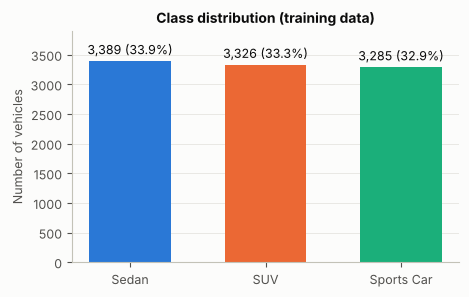

In [6]:
counts = train[TARGET].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(5, 3))
bars = ax.bar([CLASS_NAMES[c] for c in counts.index], counts.values, width=0.6,
              color=[CLASS_COLORS[c] for c in counts.index])
ax.bar_label(bars, labels=[f"{v:,} ({v / len(train):.1%})" for v in counts.values], padding=3)
ax.set_ylabel("Number of vehicles")
ax.set_title("Class distribution (training data)")
ax.set_ylim(0, counts.max() * 1.15)
ax.grid(axis="x", visible=False)
save(fig, "01_class_distribution")
plt.show()

**Observation:** The three classes are almost perfectly balanced (≈ 33% each). Accuracy is therefore a fair metric
and no re-sampling or class weighting is needed. Always predicting the most common class would score only ≈ 34% —
this is the baseline every model must beat.

## 1.4 Missing values

In [7]:
missing = pd.DataFrame({"train": train.isna().sum(), "test": test.isna().sum()})
print("Total missing — train:", int(missing["train"].sum()), "| test:", int(missing["test"].sum()))
missing[missing.sum(axis=1) > 0]

Total missing — train: 0 | test: 0


,train,test


**Observation:** There are no missing values in either the training or the test data, so no imputation is required.

## 1.5 Duplicates and the `vehicle_id` column
The competition warns that the training data contains duplicate vehicle measurements.

In [8]:
print("Fully identical rows (incl. vehicle_id):", train.duplicated().sum())
print("Is vehicle_id unique?                   ", train["vehicle_id"].is_unique)
print("Rows whose 20 features repeat a row      :", train.duplicated(subset=FEATURES).sum())
print("Rows whose features + label repeat a row :", train.duplicated(subset=FEATURES + [TARGET]).sum())

dup_groups = train[train.duplicated(subset=FEATURES, keep=False)].groupby(FEATURES)
print("Duplicate groups                         :", dup_groups.ngroups)
print("Group sizes (rows per group)             :", dup_groups.size().value_counts().to_dict())
print("Groups with conflicting labels           :", int((dup_groups[TARGET].nunique() > 1).sum()))
print("Duplicates in test                       :", test.duplicated(subset=FEATURES).sum())

Fully identical rows (incl. vehicle_id): 0
Is vehicle_id unique?                    True
Rows whose 20 features repeat a row      : 2500
Rows whose features + label repeat a row : 2500
Duplicate groups                         : 2500
Group sizes (rows per group)             : {2: 2500}
Groups with conflicting labels           : 0
Duplicates in test                       : 0


In [9]:
# Example: one duplicated vehicle appears under two different ids
example = train[train.duplicated(subset=FEATURES, keep=False)].sort_values(FEATURES).head(2)
example[["vehicle_id"] + FEATURES[:6] + [TARGET]]

,vehicle_id,engine_displacement_l,horsepower_hp,torque_nm,engine_cylinders,battery_capacity_kwh,vehicle_weight_kg,vehicle_class
2519,2520,0.9,90.0,130.0,3.0,26.0,1270.0,0
9565,9566,0.9,90.0,130.0,3.0,26.0,1270.0,0


In [10]:
# Are duplicates concentrated in one class?
is_dup = train.duplicated(subset=FEATURES, keep="first")
dup_by_class = is_dup.groupby(train[TARGET]).mean().rename(index=CLASS_NAMES)
print("Share of rows that are duplicate copies, per class:")
print(dup_by_class.map("{:.1%}".format).to_string())

# De-duplicated training data used for the rest of the EDA
df = train.drop_duplicates(subset=FEATURES).reset_index(drop=True)
print("\nRows after removing duplicates:", len(df))
print(df[TARGET].value_counts().sort_index().rename(index=CLASS_NAMES).to_string())

Share of rows that are duplicate copies, per class:
vehicle_class
Sedan         25.1%
SUV           25.1%
Sports Car    24.8%

Rows after removing duplicates: 7500
vehicle_class
Sedan         2539
SUV           2490
Sports Car    2471


In [11]:
# Does vehicle_id carry any information about the class?
id_bins = pd.qcut(train["vehicle_id"], 5)
pd.crosstab(id_bins, train[TARGET].map(CLASS_NAMES), normalize="index").round(3)

vehicle_class,SUV,Sedan,Sports Car
vehicle_id,,,
"(0.999, 2000.8]",0.332,0.344,0.324
"(2000.8, 4000.6]",0.328,0.338,0.335
"(4000.6, 6000.4]",0.328,0.348,0.324
"(6000.4, 8000.2]",0.344,0.322,0.334
"(8000.2, 10000.0]",0.332,0.342,0.326


**Observation:**
- 2,500 rows (25%) are exact copies of another row's measurements and label. Each duplicate group has exactly two
  rows, and no group has conflicting labels.
- `vehicle_id` is unique for every row, **even for the copies**, so duplicates are only visible when comparing the
  20 feature columns (a plain `train.duplicated()` finds none).
- Duplicates are spread roughly evenly across the classes, so removing them keeps the classes balanced
  (7,500 unique rows remain).
- The class mix is the same across `vehicle_id` ranges, so the id carries no class information — it is a record
  identifier and will be excluded from the features (as the competition instructs).
- **Why it matters:** if duplicates are kept, a vehicle can appear in both the training and validation fold during
  cross-validation, which inflates the validation score. All further analysis uses the 7,500 unique rows (`df`).

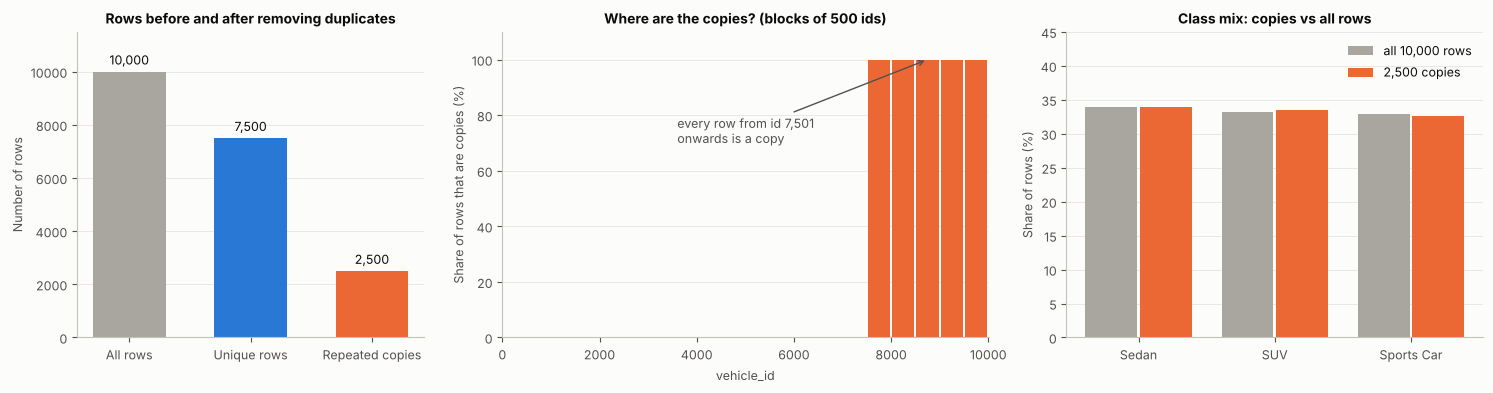

vehicle_id range of the copies: 7501 - 10000


In [12]:
# Visual summary of the duplicates
fig, axes = plt.subplots(1, 3, figsize=(15, 4), gridspec_kw={"width_ratios": [1, 1.4, 1.2]})

ax = axes[0]
vals = [len(train), (~is_dup).sum(), is_dup.sum()]
bars = ax.bar(["All rows", "Unique rows", "Repeated copies"], vals, color=[NEUTRAL, MAIN, ACCENT], width=0.6)
ax.bar_label(bars, labels=[f"{v:,}" for v in vals], padding=3)
ax.set_ylim(0, 11500)
ax.set_ylabel("Number of rows")
ax.set_title("Rows before and after removing duplicates")
ax.grid(axis="x", visible=False)

ax = axes[1]
block = (train["vehicle_id"] - 1) // 500
share = is_dup.groupby(block).mean() * 100
ax.bar(share.index * 500 + 250, share.values, width=460, color=ACCENT)
ax.set_xlim(0, 10000)
ax.set_ylim(0, 110)
ax.set_xlabel("vehicle_id")
ax.set_ylabel("Share of rows that are copies (%)")
ax.set_title("Where are the copies? (blocks of 500 ids)")
ax.annotate("every row from id 7,501\nonwards is a copy", xy=(8750, 100), xytext=(3600, 70),
            arrowprops=dict(arrowstyle="->", color=INK_2), color=INK_2, fontsize=9)
ax.grid(axis="x", visible=False)

ax = axes[2]
x = np.arange(3)
share_all = train[TARGET].value_counts(normalize=True).sort_index() * 100
share_dup = train.loc[is_dup, TARGET].value_counts(normalize=True).sort_index() * 100
ax.bar(x - 0.2, share_all, width=0.38, color=NEUTRAL, label="all 10,000 rows")
ax.bar(x + 0.2, share_dup, width=0.38, color=ACCENT, label="2,500 copies")
ax.set_xticks(x, [CLASS_NAMES[k] for k in range(3)])
ax.set_ylim(0, 45)
ax.set_ylabel("Share of rows (%)")
ax.set_title("Class mix: copies vs all rows")
ax.legend(loc="upper right")
ax.grid(axis="x", visible=False)
fig.tight_layout()
save(fig, "09_duplicates")
plt.show()
print("vehicle_id range of the copies:", train.loc[is_dup, "vehicle_id"].min(), "-", train.loc[is_dup, "vehicle_id"].max())

**Observation (chart):** all 2,500 copies sit in one block at the end of the file (`vehicle_id` 7,501–10,000), and their class mix matches the whole dataset. The training file is therefore 7,500 unique vehicles followed by 2,500 re-sampled ones — the copies add no new information, which confirms the decision to drop them.

## 1.6 Feature distributions by class

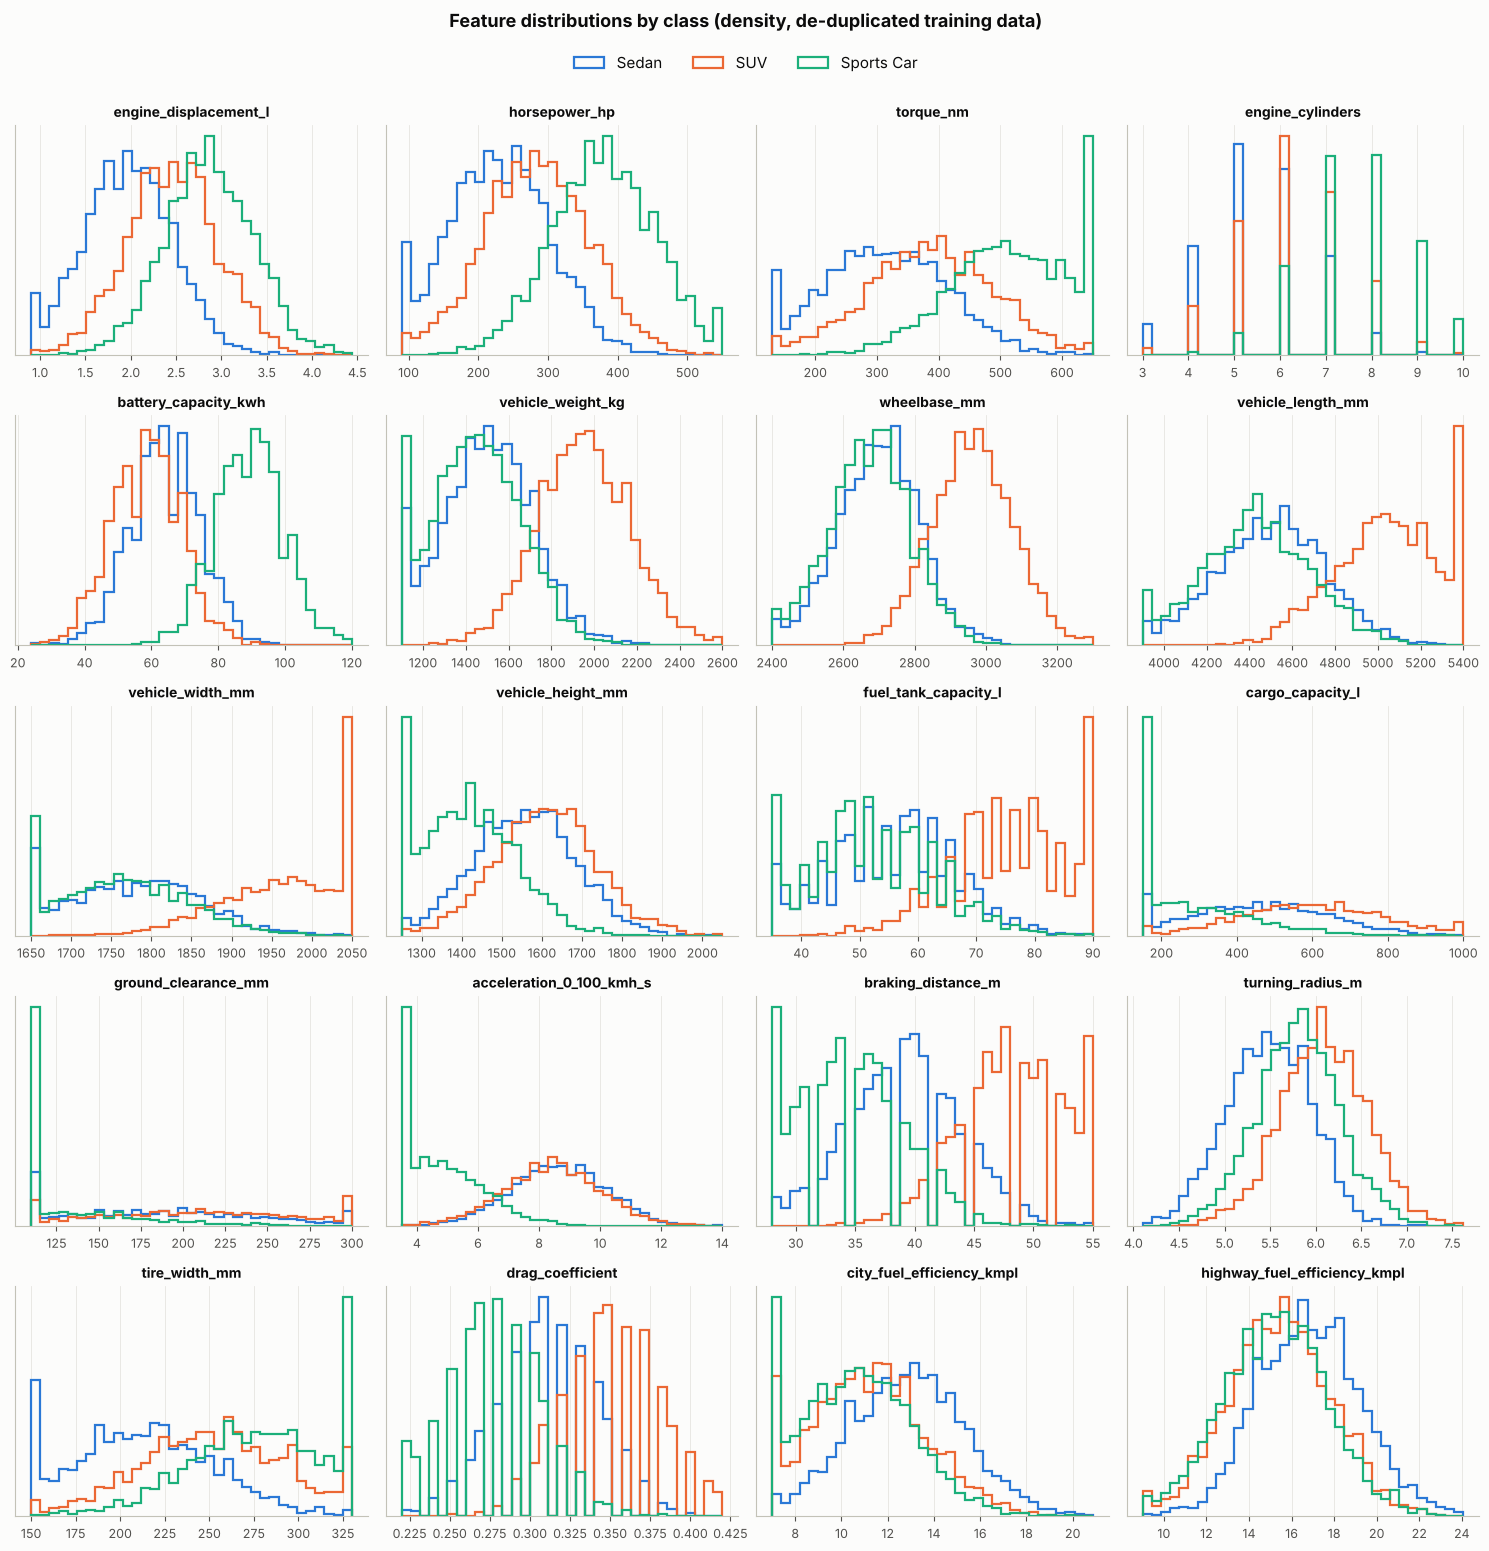

In [13]:
fig, axes = plt.subplots(5, 4, figsize=(15, 15))
for ax, feat in zip(axes.flat, FEATURES):
    bins = np.histogram_bin_edges(df[feat], bins=35)
    for c in CLASS_NAMES:
        ax.hist(df.loc[df[TARGET] == c, feat], bins=bins, histtype="step", linewidth=1.6,
                color=CLASS_COLORS[c], label=CLASS_NAMES[c], density=True)
    ax.set_title(feat)
    ax.set_yticks([])
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=3, fontsize=11, bbox_to_anchor=(0.5, 1.01))
fig.suptitle("Feature distributions by class (density, de-duplicated training data)", y=1.03, fontsize=13,
             fontweight="bold")
fig.tight_layout()
save(fig, "02_feature_distributions_by_class")
plt.show()

**Observation:**
- **Sports cars** stand apart on the engine/performance features: much higher horsepower, torque, cylinders,
  battery capacity and tire width, and much faster acceleration (lower 0–100 time) and shorter braking distance.
- **SUVs** stand apart on the size features: heavier, longer, wider, longer wheelbase, bigger fuel tank and cargo
  space, and the longest braking distance.
- **Sedans** sit in the middle — overlapping SUVs on engine features and sports cars on size features — so Sedan is
  likely the hardest class to separate.
- Every feature shows substantial **overlap between classes**; no single feature cleanly separates them.
- Several features have a **spike at one end of their range** (e.g. ground clearance at 110 mm for sports cars,
  vehicle width at 2,050 mm for SUVs), indicating capped values (Section 1.10).
- Most distributions are roughly bell-shaped within each class, which is relevant for Gaussian Bayes classifiers.
- The "comb" pattern in braking distance, drag coefficient and fuel tank capacity is only rounding (values are
  recorded as whole metres / litres or to 2 decimals), and `engine_cylinders` is discrete (3–10).

## 1.7 Class profiles (medians and box plots)

In [14]:
profile = df.groupby(TARGET)[FEATURES].median().T.rename(columns=CLASS_NAMES)
profile["highest"] = profile.idxmax(axis=1)
profile["lowest"] = profile[list(CLASS_NAMES.values())].idxmin(axis=1)
profile.round(2)

vehicle_class,Sedan,SUV,Sports Car,highest,lowest
engine_displacement_l,1.97,2.46,2.86,Sports Car,Sedan
horsepower_hp,230.00,282.00,380.00,Sports Car,Sedan
torque_nm,313.00,386.00,515.00,Sports Car,Sedan
engine_cylinders,5.00,6.00,8.00,Sports Car,Sedan
battery_capacity_kwh,64.00,59.00,89.00,Sports Car,SUV
vehicle_weight_kg,1507.00,1950.00,1452.00,SUV,Sports Car
wheelbase_mm,2703.00,2962.00,2677.00,SUV,Sports Car
vehicle_length_mm,4513.00,5052.00,4433.00,SUV,Sports Car
vehicle_width_mm,1782.00,1972.00,1763.00,SUV,Sports Car
vehicle_height_mm,1558.00,1611.00,1412.00,SUV,Sports Car


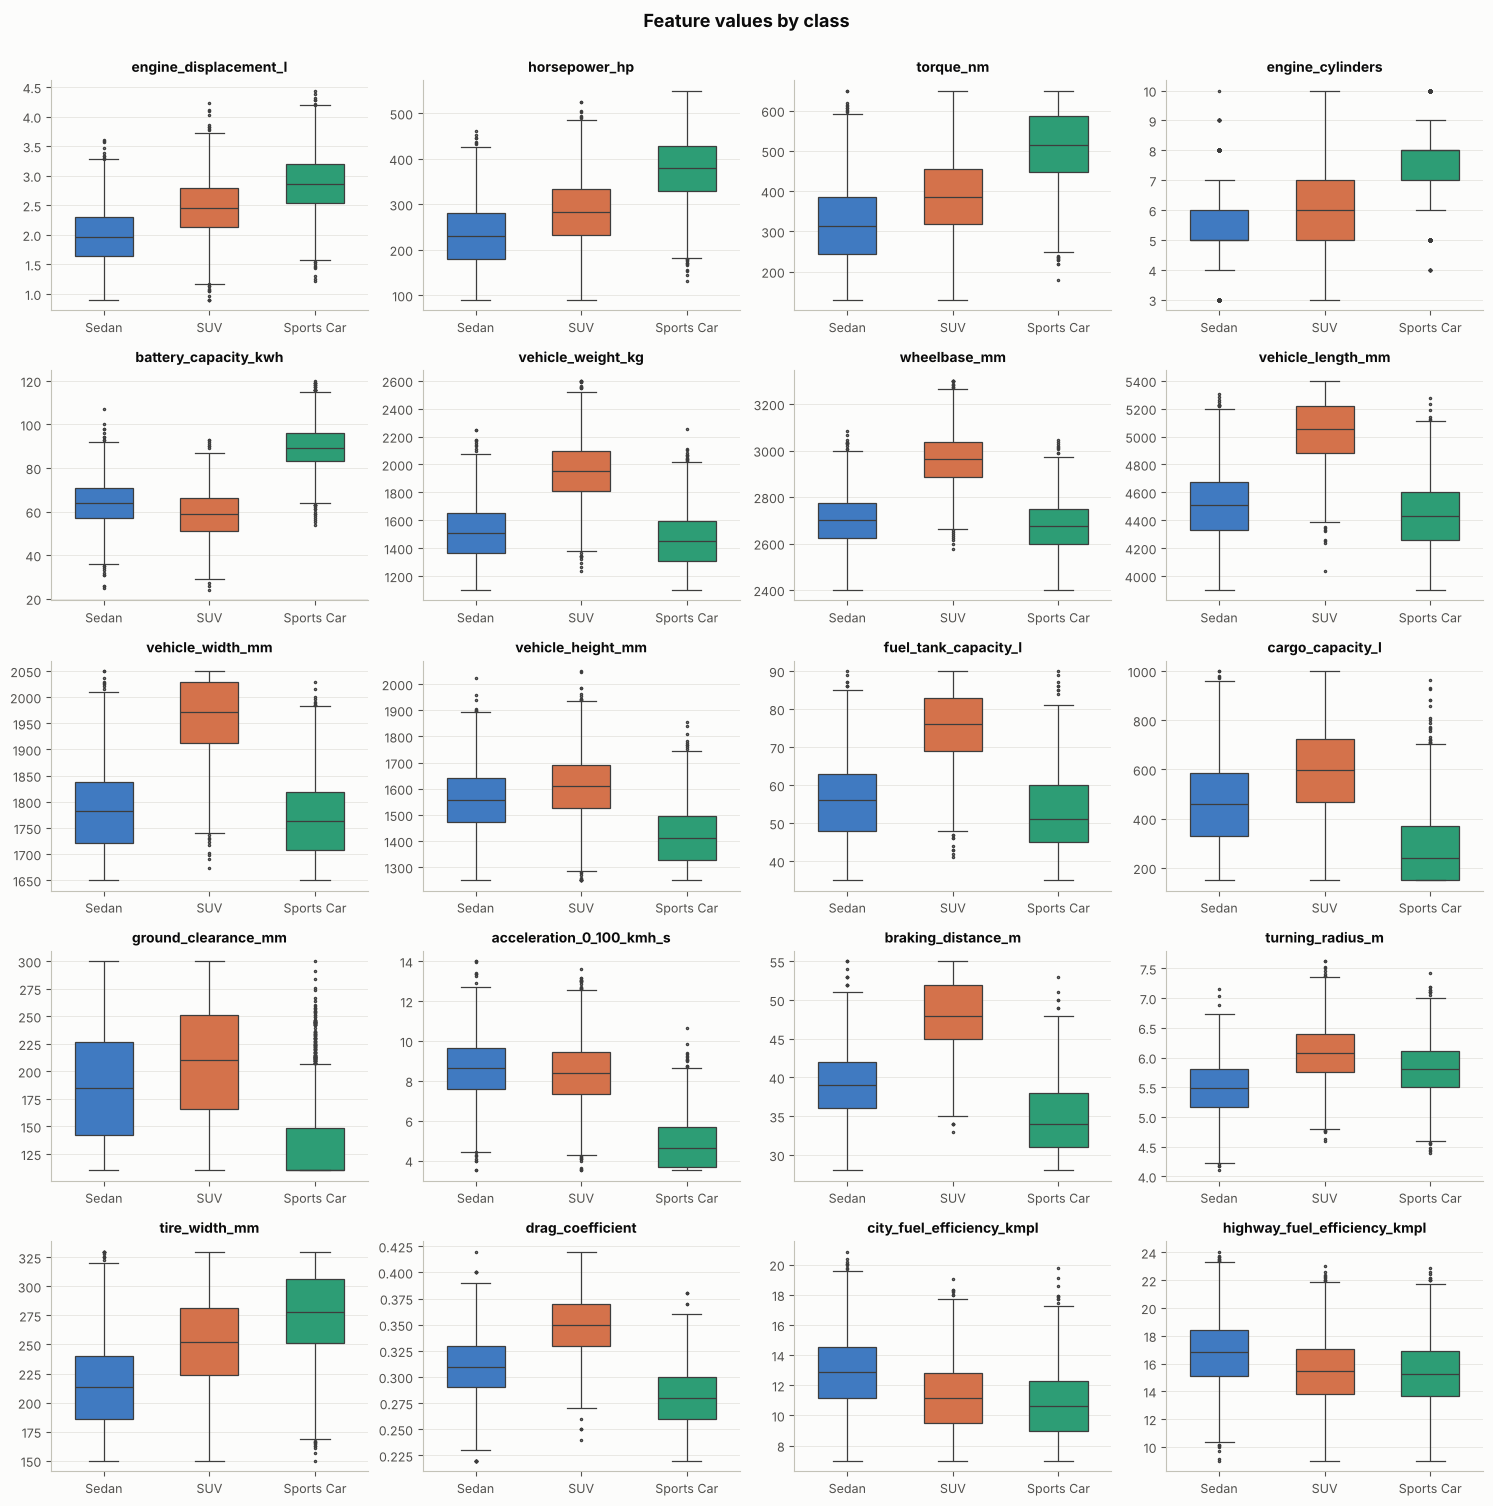

In [15]:
long = df.melt(id_vars=TARGET, value_vars=FEATURES, var_name="feature")
long["class"] = long[TARGET].map(CLASS_NAMES)
palette = {CLASS_NAMES[c]: CLASS_COLORS[c] for c in CLASS_NAMES}

fig, axes = plt.subplots(5, 4, figsize=(15, 15))
for ax, feat in zip(axes.flat, FEATURES):
    sns.boxplot(data=long[long["feature"] == feat], x="class", y="value", hue="class", palette=palette,
                order=list(palette), width=0.55, fliersize=1.5, linewidth=0.9, ax=ax, legend=False)
    ax.set_title(feat)
    ax.set_xlabel("")
    ax.set_ylabel("")
fig.suptitle("Feature values by class", y=1.0, fontsize=13, fontweight="bold")
fig.tight_layout()
save(fig, "03_boxplots_by_class")
plt.show()

**Observation:** The medians confirm the picture from Section 6:
- **Sports Car:** highest horsepower, torque, cylinders, displacement, battery capacity and tire width; lowest
  acceleration time, braking distance, height, ground clearance, cargo capacity and drag coefficient.
- **SUV:** highest weight, length, width, wheelbase, height, fuel tank, cargo capacity, ground clearance, braking
  distance, turning radius and drag coefficient.
- **Sedan:** highest fuel efficiency (city and highway); otherwise in between the other two.

In short, the classes differ along two main directions: **power/performance** (sports cars high) and
**size** (SUVs high), with sedans low on both.

**Class fingerprints.** The median table above is easier to read as a heatmap. Each value is the class median expressed in standard deviations from the overall mean (red = above average, blue = below average).

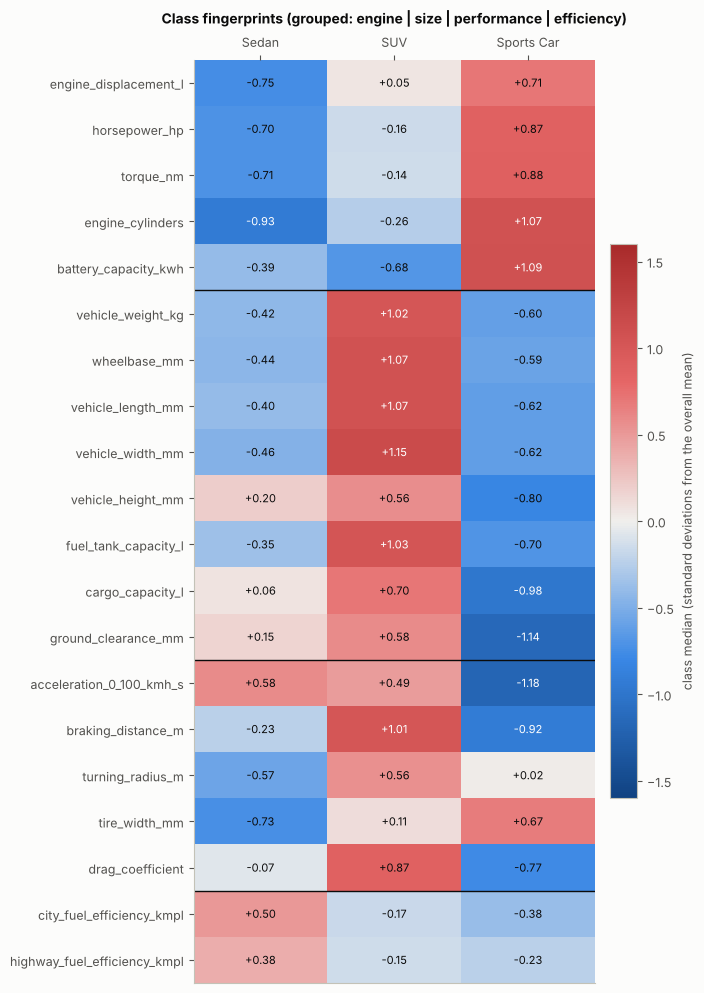

In [16]:
z = (df[FEATURES] - df[FEATURES].mean()) / df[FEATURES].std()
fp = z.groupby(df[TARGET]).median().T.rename(columns=CLASS_NAMES)

fig, ax = plt.subplots(figsize=(7, 10))
im = ax.imshow(fp.values, cmap=DIVERGING, vmin=-1.6, vmax=1.6, aspect="auto")
ax.set_xticks(range(3), fp.columns)
ax.set_yticks(range(len(fp)), fp.index)
ax.tick_params(axis="x", top=True, labeltop=True, bottom=False, labelbottom=False)
ax.grid(False)
for i in range(fp.shape[0]):
    for j in range(3):
        v = fp.iat[i, j]
        ax.text(j, i, f"{v:+.2f}", ha="center", va="center", fontsize=8, color="white" if abs(v) > 0.9 else "#0b0b0b")
for pos in np.cumsum([len(g) for g in GROUPS.values()])[:-1]:
    ax.axhline(pos - 0.5, color="#0b0b0b", linewidth=1)
cb = fig.colorbar(im, ax=ax, shrink=0.6, pad=0.03)
cb.set_label("class median (standard deviations from the overall mean)")
ax.set_title("Class fingerprints (grouped: engine | size | performance | efficiency)", pad=26)
fig.tight_layout()
save(fig, "10_class_fingerprints")
plt.show()

**Observation (heatmap):** each class has a clear fingerprint.
- **Sports Car:** red on the engine block (cylinders, battery, horsepower, torque) and deep blue on acceleration time, ground clearance, cargo and braking distance.
- **SUV:** red on the whole size block (width, length, wheelbase, fuel tank, weight ≈ +1 sd) plus braking distance and drag.
- **Sedan:** blue on the engine block (weakest engines), below-average size like the Sports Car, slow acceleration like the SUV and the best fuel efficiency — it shares part of its fingerprint with each other class, which is why it is the hardest class to separate.

## 1.8 Correlation between features

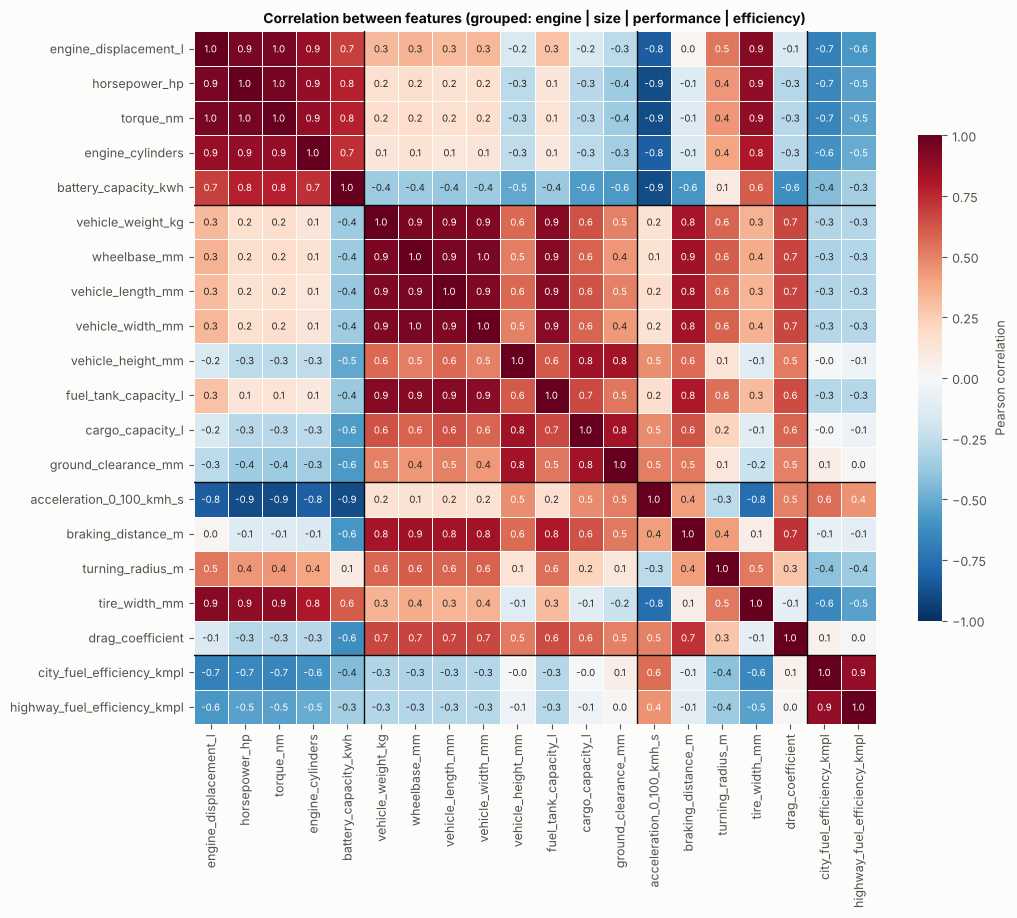

In [17]:
corr = df[FEATURES].corr()
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, cmap="RdBu_r", vmin=-1, vmax=1, center=0, annot=True, fmt=".1f", annot_kws={"size": 7},
            linewidths=0.5, linecolor="#fcfcfb", cbar_kws={"label": "Pearson correlation", "shrink": 0.7}, ax=ax)
ax.set_title("Correlation between features (grouped: engine | size | performance | efficiency)")
ax.grid(False)
for pos in np.cumsum([len(g) for g in GROUPS.values()])[:-1]:
    ax.axhline(pos, color="#0b0b0b", linewidth=1)
    ax.axvline(pos, color="#0b0b0b", linewidth=1)
save(fig, "04_correlation_heatmap")
plt.show()

In [18]:
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
         .rename("r").reset_index().rename(columns={"level_0": "feature_1", "level_1": "feature_2"}))
strong = pairs[pairs["r"].abs() > 0.9].sort_values("r", key=abs, ascending=False)
print(f"Pairs with |r| > 0.9: {len(strong)}  |  pairs with |r| > 0.8: {(pairs['r'].abs() > 0.8).sum()}")
strong.round(3)

Pairs with |r| > 0.9: 14  |  pairs with |r| > 0.8: 34


,feature_1,feature_2,r
22,horsepower_hp,torque_nm,0.959
2,engine_displacement_l,torque_nm,0.952
128,wheelbase_mm,vehicle_width_mm,0.952
1,engine_displacement_l,horsepower_hp,0.950
127,wheelbase_mm,vehicle_length_mm,0.949
106,vehicle_weight_kg,wheelbase_mm,0.945
148,vehicle_length_mm,vehicle_width_mm,0.937
107,vehicle_weight_kg,vehicle_length_mm,0.935
108,vehicle_weight_kg,vehicle_width_mm,0.929
150,vehicle_length_mm,fuel_tank_capacity_l,0.914


**Observation:**
- The features form tightly correlated **blocks**:
  - *Engine block:* horsepower, torque and displacement (r ≈ 0.95–0.96), also cylinders, tire width and acceleration.
  - *Size block:* weight, wheelbase, length, width and fuel tank (r ≈ 0.90–0.95), also braking distance.
  - *Height block:* height, ground clearance and cargo capacity (r ≈ 0.84–0.85).
  - *Efficiency:* city and highway fuel efficiency (r ≈ 0.87).
- So the 20 features carry only a few underlying "ideas" (power, size, height, efficiency) — strong
  **multicollinearity**.
- **Why it matters:** Gaussian Naive Bayes assumes features are independent within each class; this assumption is
  clearly violated, so we expect it to be over-confident and less accurate. Models that use the covariance
  (LDA/QDA) or learn weights jointly (logistic regression) handle correlated inputs better. For logistic regression,
  regularisation helps keep coefficients stable when inputs are correlated.

## 1.9 Pairwise views (power vs size)

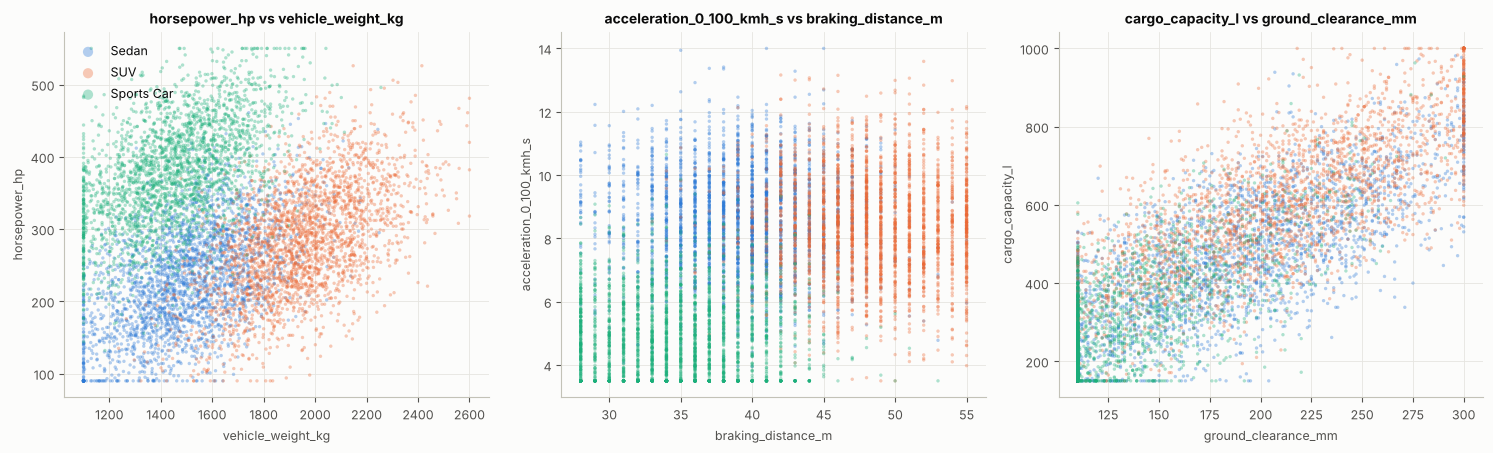

In [19]:
views = [("vehicle_weight_kg", "horsepower_hp"),
         ("braking_distance_m", "acceleration_0_100_kmh_s"),
         ("ground_clearance_mm", "cargo_capacity_l")]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, (x, y) in zip(axes, views):
    for c in CLASS_NAMES:
        sub = df[df[TARGET] == c]
        ax.scatter(sub[x], sub[y], s=6, alpha=0.35, color=CLASS_COLORS[c], label=CLASS_NAMES[c],
                   edgecolors="none")
    ax.set_xlabel(x)
    ax.set_ylabel(y)
    ax.set_title(f"{y} vs {x}")
axes[0].legend(markerscale=3, loc="upper left")
fig.tight_layout()
save(fig, "05_pairwise_scatter")
plt.show()

**Observation:**
- **Horsepower vs weight:** the clearest view of the problem. Sports cars occupy the high-power / low-weight
  region, SUVs the heavy region, sedans the low-power / low-weight corner.
- **Acceleration vs braking distance:** sports cars form a separate cluster (fast and short braking); sedans and SUVs
  overlap more and are split mostly by braking distance.
- **Clearance vs cargo:** many sports cars sit exactly at the 110 mm clearance floor (vertical line of points).
- The class clouds are roughly elliptical and their boundaries look close to **straight lines** — a hint that
  linear models (logistic regression, LDA) may work well. There is also a clear **overlap zone** where points of
  different classes mix, which sets an upper limit on achievable accuracy.

**Scatter matrix of the four most informative features.** Braking distance, battery capacity, acceleration and wheelbase are the strongest single features (Section 1.12). Plotting every pair shows how they work together.

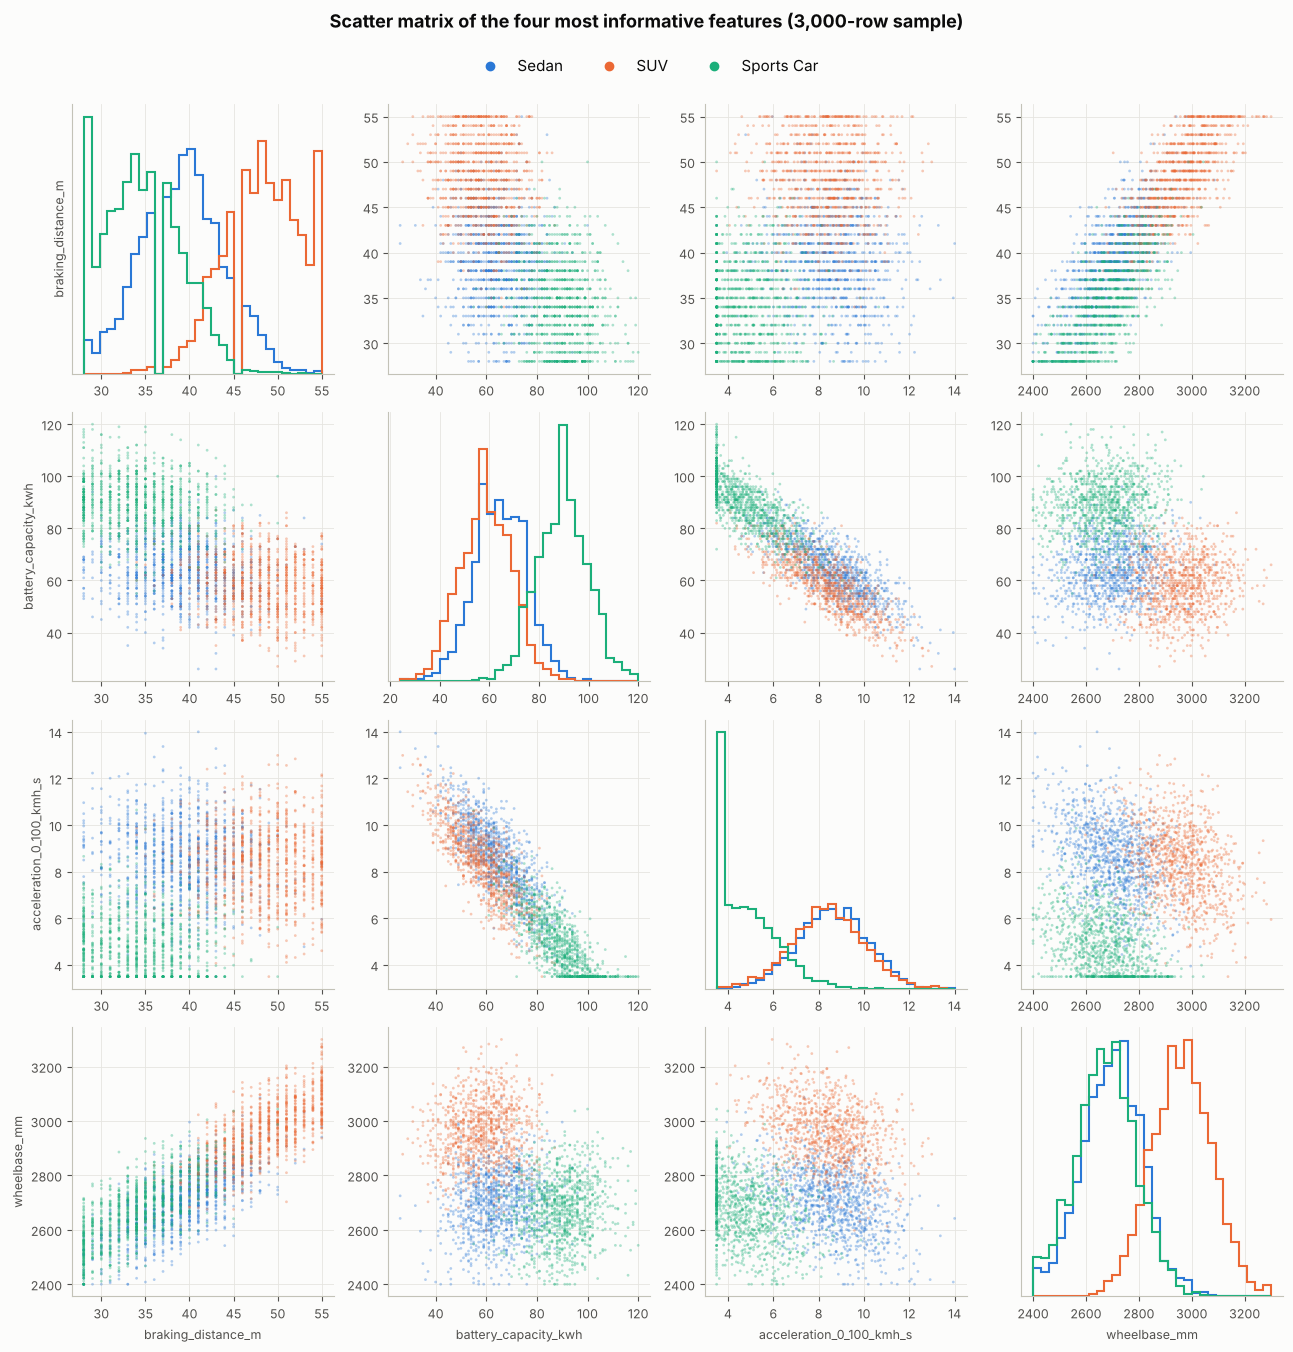

In [20]:
top4 = ["braking_distance_m", "battery_capacity_kwh", "acceleration_0_100_kmh_s", "wheelbase_mm"]
sample = df.sample(3000, random_state=42)          # a sample keeps the plot readable
fig, axes = plt.subplots(4, 4, figsize=(13, 13))
for i, fy in enumerate(top4):
    for j, fx in enumerate(top4):
        ax = axes[i, j]
        if i == j:
            bins = np.histogram_bin_edges(df[fx], bins=30)
            for c in CLASS_NAMES:
                ax.hist(df.loc[df[TARGET] == c, fx], bins=bins, histtype="step", linewidth=1.5,
                        density=True, color=CLASS_COLORS[c])
            ax.set_yticks([])
        else:
            for c in CLASS_NAMES:
                s = sample[sample[TARGET] == c]
                ax.scatter(s[fx], s[fy], s=4, alpha=0.35, color=CLASS_COLORS[c], edgecolors="none",
                           label=CLASS_NAMES[c])
        if i == 3:
            ax.set_xlabel(fx)
        if j == 0:
            ax.set_ylabel(fy)
handles = [plt.Line2D([], [], marker="o", linestyle="", color=CLASS_COLORS[c], label=CLASS_NAMES[c]) for c in CLASS_NAMES]
fig.legend(handles=handles, loc="upper center", ncol=3, fontsize=11, bbox_to_anchor=(0.5, 1.01))
fig.suptitle("Scatter matrix of the four most informative features (3,000-row sample)", y=1.035,
             fontsize=13, fontweight="bold")
fig.tight_layout()
save(fig, "11_scatter_matrix_top4")
plt.show()

**Observation:** combining two strong features already separates most vehicles. **Battery capacity** and **acceleration** isolate the Sports Cars (large battery, fast acceleration), while **braking distance** and **wheelbase** separate SUVs (long braking distance, long wheelbase) from Sedans. The remaining overlap is again between Sedans and the class they resemble on that pair of features.

## 1.10 Capped values (range limits)

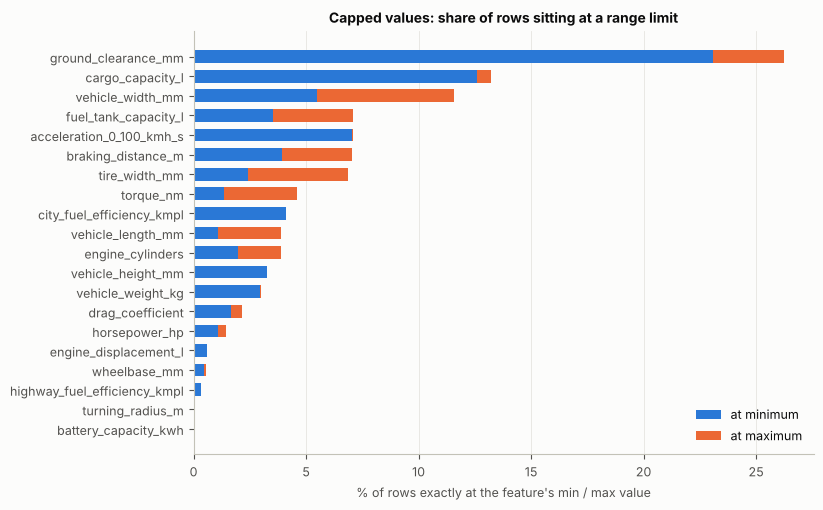

,min,max,% at min,% at max,% at a bound
ground_clearance_mm,110.00,300.00,23.08,3.16,26.24
cargo_capacity_l,150.00,1000.00,12.61,0.60,13.21
vehicle_width_mm,1650.00,2050.00,5.48,6.08,11.56
fuel_tank_capacity_l,35.00,90.00,3.55,3.56,7.11
acceleration_0_100_kmh_s,3.50,14.00,7.05,0.03,7.08
braking_distance_m,28.00,55.00,3.95,3.08,7.03
tire_width_mm,150.00,330.00,2.41,4.47,6.88
torque_nm,130.00,650.00,1.37,3.24,4.61
city_fuel_efficiency_kmpl,7.00,20.87,4.11,0.01,4.12
vehicle_length_mm,3900.00,5400.00,1.07,2.83,3.89


In [21]:
bounds = pd.DataFrame({
    "min": df[FEATURES].min(), "max": df[FEATURES].max(),
    "% at min": (df[FEATURES] == df[FEATURES].min()).mean() * 100,
    "% at max": (df[FEATURES] == df[FEATURES].max()).mean() * 100,
})
bounds["% at a bound"] = bounds["% at min"] + bounds["% at max"]
bounds = bounds.sort_values("% at a bound", ascending=False)

fig, ax = plt.subplots(figsize=(8, 5.5))
show = bounds[bounds["% at a bound"] > 0].iloc[::-1]
ax.barh(show.index, show["% at min"], color="#2a78d6", label="at minimum", height=0.65)
ax.barh(show.index, show["% at max"], left=show["% at min"], color="#eb6834", label="at maximum", height=0.65)
ax.set_xlabel("% of rows exactly at the feature's min / max value")
ax.set_title("Capped values: share of rows sitting at a range limit")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
save(fig, "06_capped_values")
plt.show()
bounds.round(2)

In [22]:
# Which classes sit at the most-capped bounds?
for feat, side in [("ground_clearance_mm", "min"), ("vehicle_width_mm", "max"), ("cargo_capacity_l", "min")]:
    limit = df[feat].min() if side == "min" else df[feat].max()
    at = df[df[feat] == limit][TARGET].map(CLASS_NAMES).value_counts()
    print(f"{feat} = {limit} ({side}): {at.to_dict()}")

ground_clearance_mm = 110.0 (min): {'Sports Car': 1295, 'Sedan': 296, 'SUV': 140}
vehicle_width_mm = 2050.0 (max): {'SUV': 454, 'Sedan': 2}
cargo_capacity_l = 150.0 (min): {'Sports Car': 783, 'Sedan': 136, 'SUV': 27}


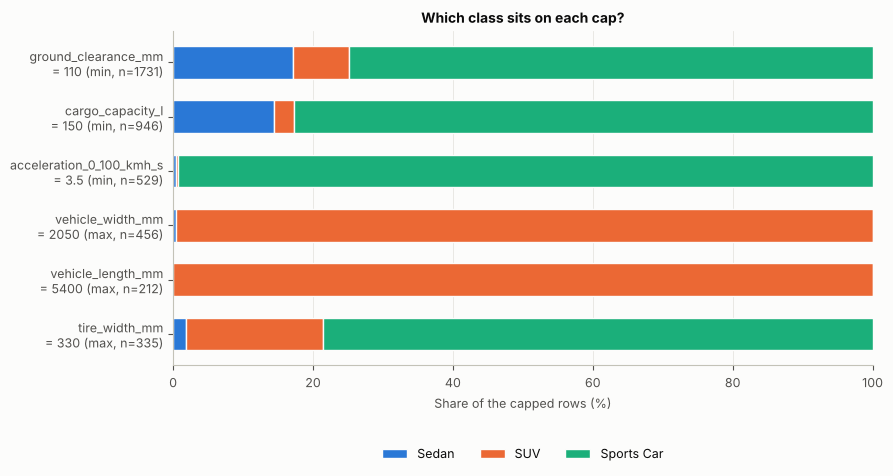

In [23]:
# Class composition of the most heavily capped values (chart of the printed counts above)
caps = [("ground_clearance_mm", "min"), ("cargo_capacity_l", "min"), ("acceleration_0_100_kmh_s", "min"),
        ("vehicle_width_mm", "max"), ("vehicle_length_mm", "max"), ("tire_width_mm", "max")]
rows = {}
for feat, side in caps:
    limit = df[feat].min() if side == "min" else df[feat].max()
    m = df[feat] == limit
    rows[f"{feat}\n= {limit:g} ({side}, n={m.sum()})"] = df.loc[m, TARGET].value_counts(normalize=True).reindex(range(3), fill_value=0) * 100

comp = pd.DataFrame(rows).T
fig, ax = plt.subplots(figsize=(9, 5))
left = np.zeros(len(comp))
for c in CLASS_NAMES:
    ax.barh(comp.index, comp[c], left=left, color=CLASS_COLORS[c], label=CLASS_NAMES[c], height=0.6,
            edgecolor="#fcfcfb", linewidth=1)
    left += comp[c].values
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("Share of the capped rows (%)")
ax.set_title("Which class sits on each cap?")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.32), ncol=3)
ax.grid(axis="y", visible=False)
fig.tight_layout()
save(fig, "12_capped_values_by_class")
plt.show()

**Observation:**
- Many features have a noticeable pile-up of values at exactly their minimum or maximum (e.g. about a quarter of
  rows have ground clearance at the 110 mm floor or 300 mm ceiling). The data generator clipped values to fixed
  realistic ranges.
- The capped values are strongly class-specific: about 75% of vehicles at the 110 mm ground-clearance floor and
  over 80% at the 150 L cargo floor are sports cars, and almost every vehicle at the 2,050 mm width ceiling is an
  SUV. So they are informative, not errors.
- **Decision:** keep the capped values unchanged. They are valid measurements within realistic limits.

## 1.11 Outliers

In [24]:
q1, q3 = df[FEATURES].quantile(0.25), df[FEATURES].quantile(0.75)
iqr = q3 - q1
iqr_out = (df[FEATURES] < q1 - 1.5 * iqr) | (df[FEATURES] > q3 + 1.5 * iqr)
z_out = ((df[FEATURES] - df[FEATURES].mean()) / df[FEATURES].std()).abs() > 3

outliers = pd.DataFrame({"IQR outliers": iqr_out.sum(), "|z| > 3": z_out.sum()})
print("Rows with at least one IQR outlier:", int(iqr_out.any(axis=1).sum()), "of", len(df))
print("Rows with at least one |z| > 3    :", int(z_out.any(axis=1).sum()), "of", len(df))
outliers[outliers.sum(axis=1) > 0].sort_values("IQR outliers", ascending=False)

Rows with at least one IQR outlier: 135 of 7500
Rows with at least one |z| > 3    : 52 of 7500


,IQR outliers,|z| > 3
highway_fuel_efficiency_kmpl,49,9
turning_radius_m,39,14
city_fuel_efficiency_kmpl,27,13
engine_displacement_l,18,5
vehicle_weight_kg,13,9
vehicle_height_mm,8,5
wheelbase_mm,6,6


In [25]:
# Class mix of the rows flagged as IQR outliers vs. overall
pd.DataFrame({"outlier rows": df.loc[iqr_out.any(axis=1), TARGET].map(CLASS_NAMES).value_counts(normalize=True),
              "all rows": df[TARGET].map(CLASS_NAMES).value_counts(normalize=True)}).round(3)

,outlier rows,all rows
vehicle_class,,
Sedan,0.407,0.339
SUV,0.385,0.332
Sports Car,0.207,0.329


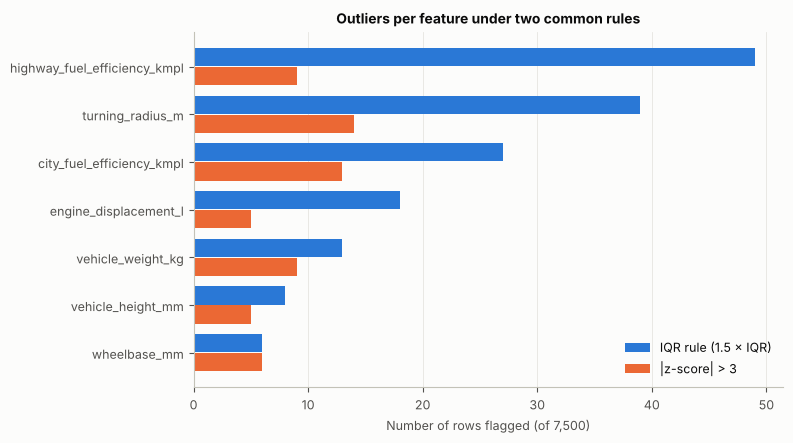

In [26]:
fig, ax = plt.subplots(figsize=(8, 4.5))
o = outliers[outliers.sum(axis=1) > 0].sort_values("IQR outliers")
y = np.arange(len(o))
ax.barh(y + 0.2, o["IQR outliers"], height=0.38, color=MAIN, label="IQR rule (1.5 × IQR)")
ax.barh(y - 0.2, o["|z| > 3"], height=0.38, color=ACCENT, label="|z-score| > 3")
ax.set_yticks(y, o.index)
ax.set_xlabel("Number of rows flagged (of 7,500)")
ax.set_title("Outliers per feature under two common rules")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
fig.tight_layout()
save(fig, "13_outliers")
plt.show()

**Observation:**
- Fewer than 2% of rows contain any IQR outlier, mostly in fuel efficiency and turning radius. All values are still
  physically plausible and within the clipped ranges seen above.
- **Decision:** do **not** remove outliers. They are genuine (synthetic) vehicles, not recording errors, and the
  test data is *noisier* than the training data — removing extreme training points would make models less prepared
  for unusual test inputs.

## 1.12 How well does each feature separate the classes on its own?
For each feature alone, the 5-fold cross-validated accuracy of a shallow decision tree (depth 3). This is a quick
measure of each feature's individual predictive power (it is an EDA tool, not one of our final models).

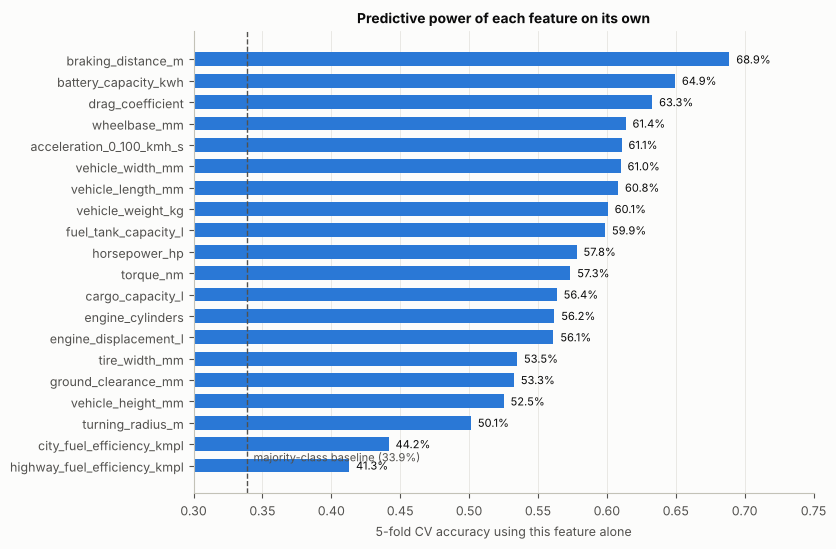

In [27]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
single = pd.Series({f: cross_val_score(DecisionTreeClassifier(max_depth=3, random_state=42),
                                       df[[f]], df[TARGET], cv=cv).mean() for f in FEATURES}).sort_values()
baseline = df[TARGET].value_counts(normalize=True).max()

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(single.index, single.values, color="#2a78d6", height=0.65)
ax.axvline(baseline, color="#52514e", linestyle="--", linewidth=1)
ax.text(baseline + 0.005, 0.2, f"majority-class baseline ({baseline:.1%})", color="#52514e", fontsize=8)
for y, v in enumerate(single.values):
    ax.text(v + 0.005, y, f"{v:.1%}", va="center", fontsize=8, color="#0b0b0b")
ax.set_xlim(0.3, 0.75)
ax.set_xlabel("5-fold CV accuracy using this feature alone")
ax.set_title("Predictive power of each feature on its own")
ax.grid(axis="y", visible=False)
save(fig, "07_single_feature_accuracy")
plt.show()

**Observation:**
- The best single features are **braking distance**, **battery capacity**, **drag coefficient**, acceleration and
  the size features — each reaches only about 60–69% accuracy on its own.
- **Fuel efficiency** (city/highway) is the weakest, barely above the 34% baseline.
- No single feature comes close to solving the problem. Good accuracy will require **combining** features, which
  every model we use (Bayes, logistic regression, decision trees) does.

**A second, model-free view of relevance.** Mutual information measures how much knowing a feature reduces uncertainty about the class (0 = no information); the ANOVA F-statistic measures how far apart the class means are relative to the spread inside each class.

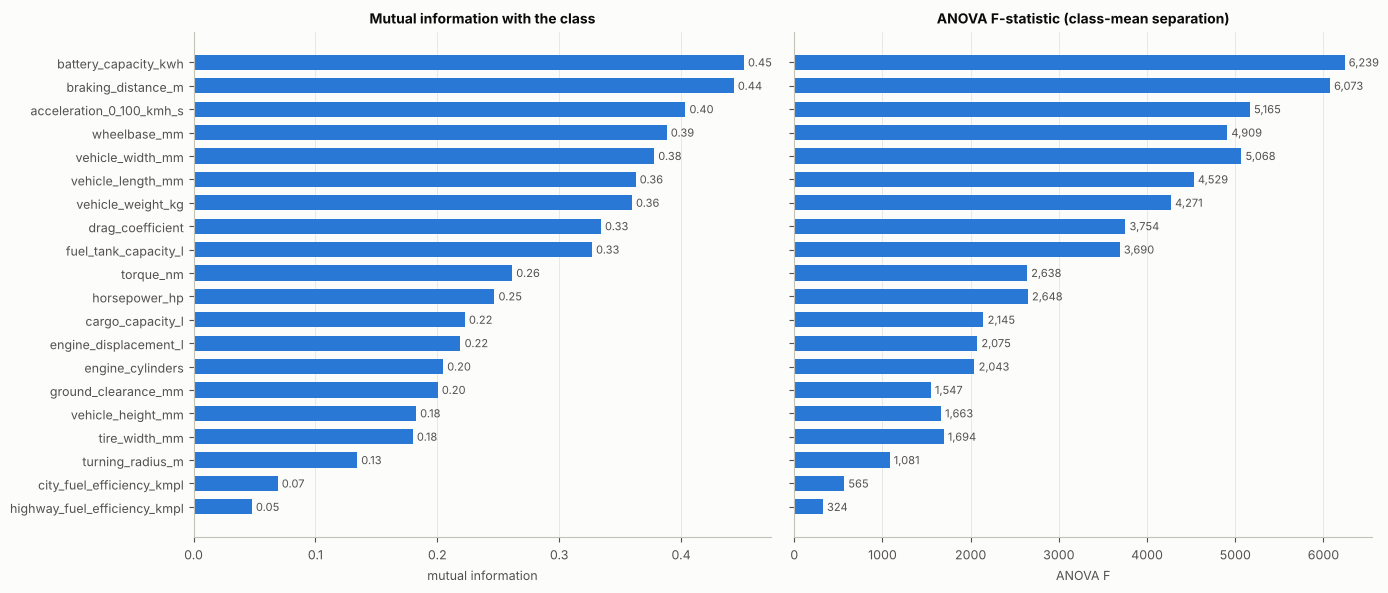

Rank correlation between the three relevance measures:


,mutual information,ANOVA F,single-feature tree accuracy
mutual information,1.00,0.99,0.97
ANOVA F,0.99,1.00,0.97
single-feature tree accuracy,0.97,0.97,1.00


In [28]:
from sklearn.feature_selection import mutual_info_classif, f_classif

rel = pd.DataFrame({
    "mutual information": mutual_info_classif(df[FEATURES], df[TARGET], random_state=42),
    "ANOVA F": f_classif(df[FEATURES], df[TARGET])[0],
    "single-feature tree accuracy": single.reindex(FEATURES).values,
}, index=FEATURES).sort_values("mutual information")

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
for ax, col, color in [(axes[0], "mutual information", MAIN), (axes[1], "ANOVA F", MAIN)]:
    bars = ax.barh(rel.index, rel[col], color=color, height=0.65)
    ax.bar_label(bars, labels=[f"{v:.2f}" if col == "mutual information" else f"{v:,.0f}" for v in rel[col]],
                 padding=3, fontsize=8, color=INK_2)
    ax.set_xlabel(col)
    ax.grid(axis="y", visible=False)
axes[0].set_title("Mutual information with the class")
axes[1].set_title("ANOVA F-statistic (class-mean separation)")
fig.tight_layout()
save(fig, "14_feature_relevance")
plt.show()
print("Rank correlation between the three relevance measures:")
rel.rank().corr(method="spearman").round(2)

**Observation:** all three measures agree: **battery capacity, braking distance and acceleration** are the most informative features, followed by the size block (wheelbase, width, length, weight); the two **fuel-efficiency** features are the least informative (mutual information 0.05–0.07). The rankings agree almost perfectly (Spearman rank correlation 0.97–0.99), so the ranking is a property of the data rather than of one method.

## 1.12b Overall class separability (PCA and LDA projections)

Two 2-D views of all 20 features at once:
- **PCA** (unsupervised) keeps the directions of largest variance, without using the labels — it shows the natural structure of the data;
- **LDA** (supervised) finds the two directions that best separate the classes — it shows the best a *linear* model can do.

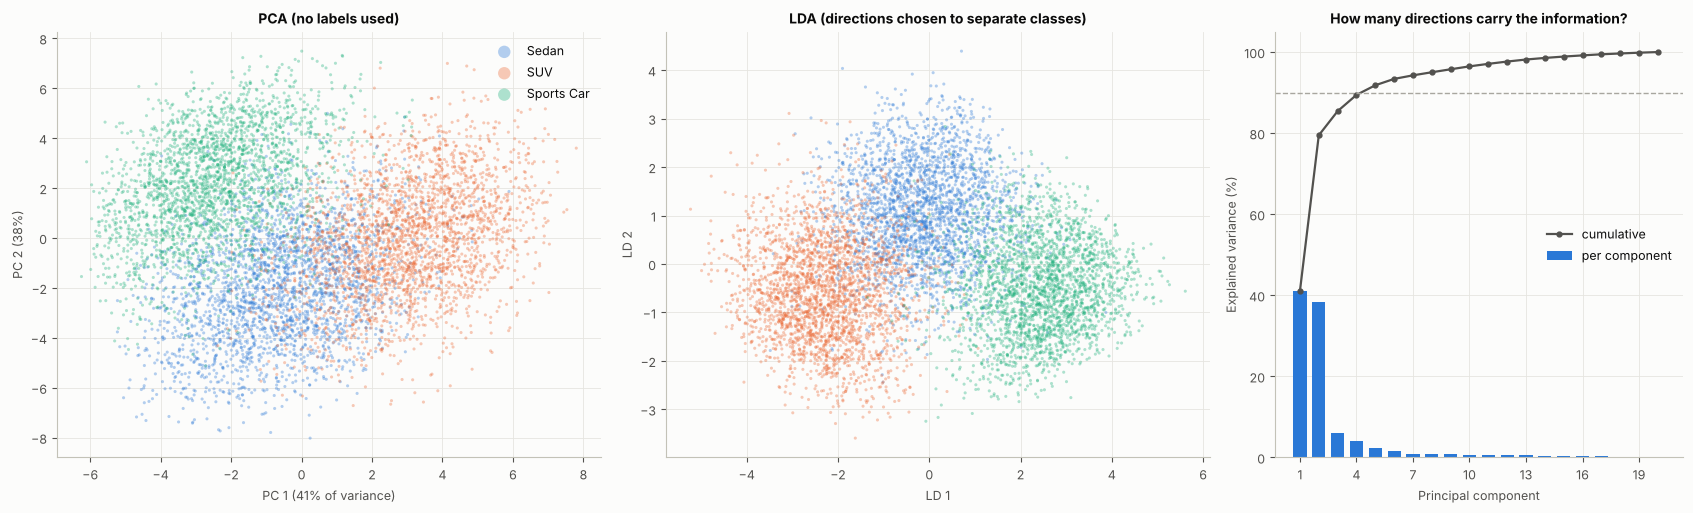

PC1 + PC2 explain 79.5% of the variance; 5 components explain 90%.
5-fold CV accuracy of a plain LDA on all 20 features: 89.2%


In [29]:
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.preprocessing import StandardScaler

Zs = StandardScaler().fit_transform(df[FEATURES])
pca = PCA(random_state=42).fit(Zs)
P = pca.transform(Zs)[:, :2]
evr = pca.explained_variance_ratio_
lda = LinearDiscriminantAnalysis().fit(Zs, df[TARGET])
L = lda.transform(Zs)

fig, axes = plt.subplots(1, 3, figsize=(17, 5.2), gridspec_kw={"width_ratios": [1.2, 1.2, 0.9]})
for ax, data, title, xl, yl in [
        (axes[0], P, "PCA (no labels used)", f"PC 1 ({evr[0]:.0%} of variance)", f"PC 2 ({evr[1]:.0%})"),
        (axes[1], L, "LDA (directions chosen to separate classes)", "LD 1", "LD 2")]:
    for c in CLASS_NAMES:
        m = (df[TARGET] == c).to_numpy()
        ax.scatter(data[m, 0], data[m, 1], s=5, alpha=0.35, color=CLASS_COLORS[c], label=CLASS_NAMES[c],
                   edgecolors="none")
    ax.set_title(title)
    ax.set_xlabel(xl)
    ax.set_ylabel(yl)
axes[0].legend(markerscale=4, loc="upper right")

ax = axes[2]
n = np.arange(1, len(evr) + 1)
ax.bar(n, evr * 100, color=MAIN, width=0.7, label="per component")
ax.plot(n, np.cumsum(evr) * 100, color=INK_2, marker="o", markersize=3.5, linewidth=1.6, label="cumulative")
ax.axhline(90, color=NEUTRAL, linestyle="--", linewidth=1)
ax.set_xticks(n[::3])
ax.set_xlabel("Principal component")
ax.set_ylabel("Explained variance (%)")
ax.set_title("How many directions carry the information?")
ax.legend(loc="center right")
fig.tight_layout()
save(fig, "15_pca_lda_projection")
plt.show()

n90 = int(np.searchsorted(np.cumsum(evr), 0.9) + 1)
lda_acc = cross_val_score(LinearDiscriminantAnalysis(), Zs, df[TARGET], cv=cv).mean()
print(f"PC1 + PC2 explain {evr[:2].sum():.1%} of the variance; {n90} components explain 90%.")
print(f"5-fold CV accuracy of a plain LDA on all 20 features: {lda_acc:.1%}")

**Observation:**
- **PCA:** only two directions explain about **80%** of the variance (5 explain 90%) — the 20 features really describe a few underlying properties (size and power), as the correlation blocks suggested. Even without labels the three classes form three visible clouds.
- **LDA:** the supervised projection separates the classes better — Sports Cars and SUVs sit at opposite ends — but **Sedans remain in the middle and overlap with both**. A plain linear classifier on all 20 features reaches about **89–90%** cross-validated accuracy, much higher than any single feature (≤ 69%).
- **Implication:** linear models are a strong starting point, and the overlap zone around the Sedans sets a practical **ceiling of roughly 90%** accuracy on clean data.

## 1.13 Train vs test: evidence of measurement noise
The competition says the evaluation data has **extra random measurement error**. If a test value = true value +
independent noise, then the test variance should be larger:
$\sigma^2_{test} = \sigma^2_{train} + \sigma^2_{noise}$, so $\sigma_{noise} = \sqrt{\sigma^2_{test} - \sigma^2_{train}}$.

With 2,500 test and 7,500 train rows, the standard deviation ratio has a sampling uncertainty of about ±0.016
(1 standard error), so only ratios clearly above ≈ 1.03 are strong evidence of extra noise.

In [30]:
n_tr, n_te = len(df), len(test)
se_ratio = np.sqrt(1 / (2 * n_tr) + 1 / (2 * n_te))   # approx. standard error of the sd ratio

shift = pd.DataFrame({
    "train mean": df[FEATURES].mean(), "test mean": test[FEATURES].mean(),
    "train sd": df[FEATURES].std(), "test sd": test[FEATURES].std(),
})
shift["sd ratio (test/train)"] = shift["test sd"] / shift["train sd"]
shift["est. noise sd / train sd"] = np.sqrt((shift["test sd"] ** 2 - shift["train sd"] ** 2).clip(lower=0)) / shift["train sd"]
shift["test values outside train range"] = [int(((test[f] < df[f].min()) | (test[f] > df[f].max())).sum())
                                           for f in FEATURES]
shift = shift.sort_values("sd ratio (test/train)", ascending=False)
print(f"Approx. standard error of the sd ratio: {se_ratio:.3f}")
shift.round(3)

Approx. standard error of the sd ratio: 0.016


,train mean,test mean,train sd,test sd,sd ratio (test/train),est. noise sd / train sd,test values outside train range
engine_displacement_l,2.427,2.444,0.611,0.635,1.038,0.280,1
highway_fuel_efficiency_kmpl,15.852,15.787,2.499,2.578,1.031,0.253,1
engine_cylinders,6.391,6.412,1.502,1.548,1.031,0.251,0
horsepower_hp,296.794,298.800,95.121,97.973,1.030,0.247,0
torque_nm,403.492,405.716,127.072,130.828,1.030,0.245,0
tire_width_mm,247.092,248.186,46.456,47.701,1.027,0.233,0
battery_capacity_kwh,70.588,70.807,16.936,17.279,1.020,0.202,0
city_fuel_efficiency_kmpl,11.609,11.506,2.555,2.595,1.016,0.179,0
acceleration_0_100_kmh_s,7.313,7.289,2.258,2.277,1.009,0.133,0
vehicle_weight_kg,1636.641,1643.927,305.769,308.285,1.008,0.129,0


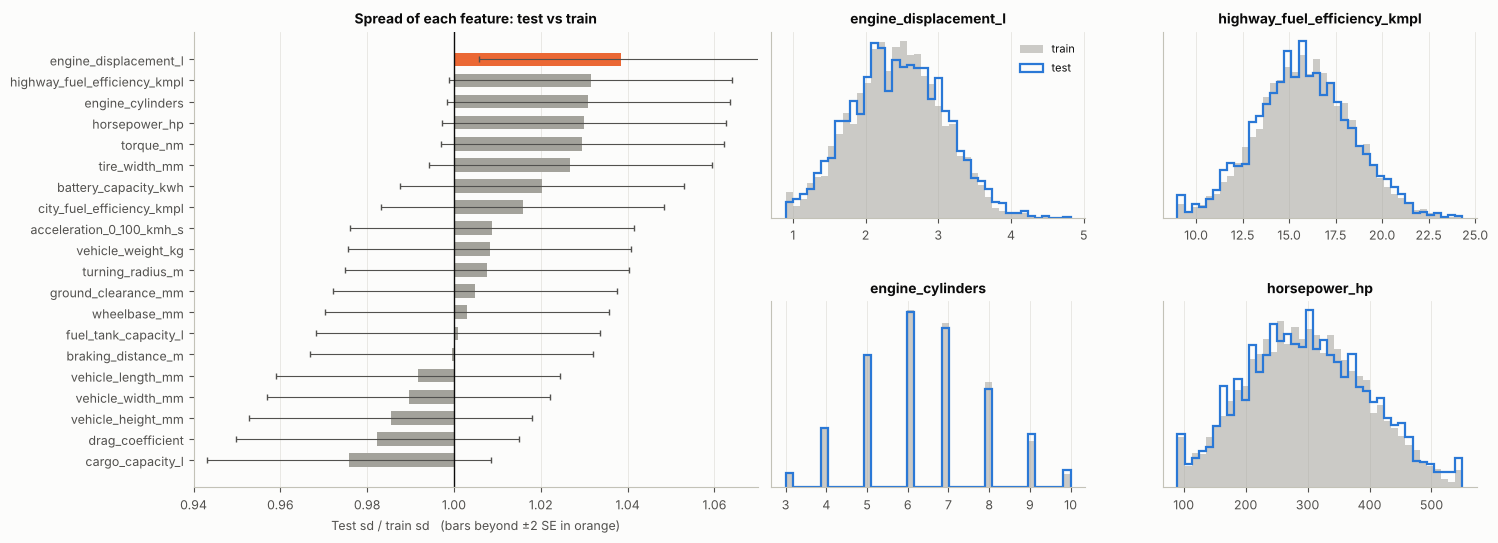

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1, 1.25]})

ax = axes[0]
r = shift["sd ratio (test/train)"].iloc[::-1]
colors = ["#eb6834" if v > 1 + 2 * se_ratio else "#a3a29b" for v in r.values]
ax.barh(r.index, r.values - 1, left=1, color=colors, height=0.65,
        xerr=2 * se_ratio, error_kw={"elinewidth": 0.8, "ecolor": "#52514e", "capsize": 2})
ax.axvline(1, color="#0b0b0b", linewidth=1)
ax.set_xlim(0.94, 1.07)
ax.set_xlabel("Test sd / train sd   (bars beyond ±2 SE in orange)")
ax.set_title("Spread of each feature: test vs train")
ax.grid(axis="y", visible=False)

# Overlay train vs test distributions for the features with the largest increase in spread
ax = axes[1]
ax.axis("off")
top = shift.index[:4]
inner = axes[1].get_subplotspec().subgridspec(2, 2, hspace=0.45, wspace=0.25)
for i, feat in enumerate(top):
    a = fig.add_subplot(inner[i // 2, i % 2])
    bins = np.histogram_bin_edges(pd.concat([df[feat], test[feat]]), bins=40)
    a.hist(df[feat], bins=bins, density=True, histtype="stepfilled", color="#a3a29b", alpha=0.55, label="train")
    a.hist(test[feat], bins=bins, density=True, histtype="step", color="#2a78d6", linewidth=1.6, label="test")
    a.set_title(feat)
    a.set_yticks([])
    if i == 0:
        a.legend(fontsize=8)
fig.tight_layout()
save(fig, "08_train_vs_test_spread")
plt.show()

**Observation:**
- The test feature **means** match the training means closely, so there is no systematic shift in the type of
  vehicles — the test vehicles come from the same population.
- The test **spread** is larger than the training spread for the engine/performance features (engine displacement,
  highway efficiency, cylinders, horsepower, torque, tire width, battery capacity): sd ratios ≈ 1.02–1.04.
- Individually, only engine displacement is clearly beyond ±2 standard errors; the others are borderline (≈ 2 SE).
  But the **pattern** is consistent — all seven engine/performance features increase together while the size
  features (length, width, height, cargo, drag) do not. Taken together this is good evidence of **added random
  measurement noise of roughly 0.2–0.25 training standard deviations** on those features. These per-feature
  estimates are rough, so we will test models over a *range* of noise levels rather than trusting exact values.
- The overlaid histograms look very similar — the noise is modest, but it blurs class boundaries slightly.
- **Why it matters:** models that rely on very precise thresholds or complex boundaries (e.g. deep decision trees)
  will lose accuracy on the noisy evaluation data. We will therefore:
  1. validate every model on **noise-injected** validation folds as well as clean ones, and
  2. try **noise augmentation** (training on extra copies of the data with small random noise added).

**What does this noise do to the classes?** We add the estimated test noise (≈ 0.25 × std on the seven engine/performance features) to the training data and compare a key pair of features before and after. This simulates what a model will see at test time.

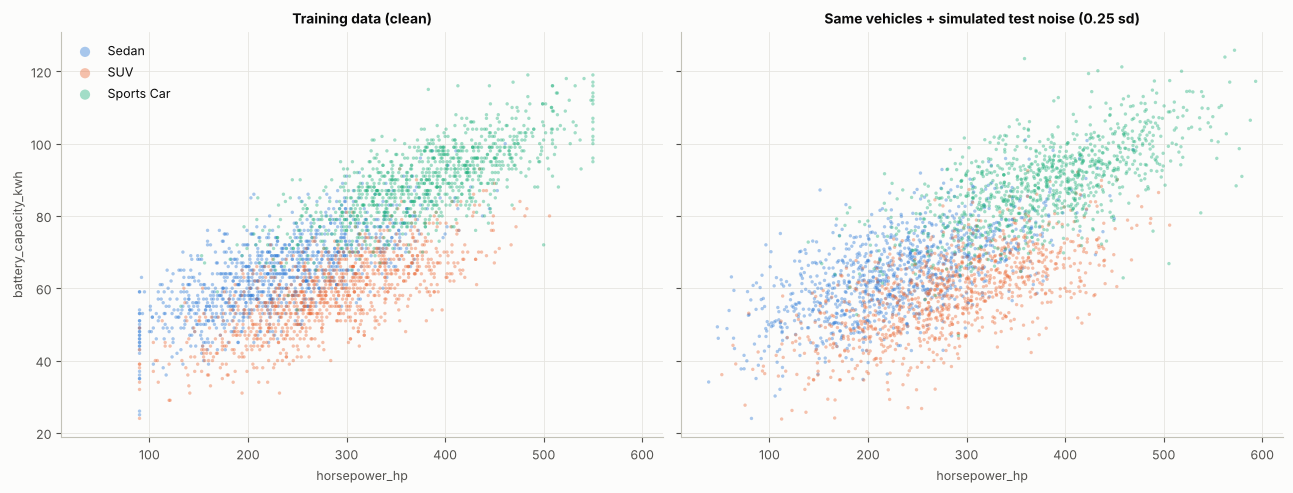

Plain LDA trained on clean data: CV accuracy on clean data 89.2%
Same model scored on the noisy copy of the training data: 89.2%  (vs 89.4% on the clean copy)


In [32]:
noisy_feats = list(shift.index[:7])
rng = np.random.default_rng(42)
df_noisy = df.copy()
for f in noisy_feats:
    df_noisy[f] = df[f] + rng.normal(0, 0.25 * df[f].std(), len(df))

pair = ("horsepower_hp", "battery_capacity_kwh")
sample_idx = df.sample(3000, random_state=1).index
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)
for ax, data, title in [(axes[0], df, "Training data (clean)"),
                        (axes[1], df_noisy, "Same vehicles + simulated test noise (0.25 sd)")]:
    for c in CLASS_NAMES:
        s = data.loc[sample_idx][data.loc[sample_idx, TARGET] == c]
        ax.scatter(s[pair[0]], s[pair[1]], s=6, alpha=0.4, color=CLASS_COLORS[c], label=CLASS_NAMES[c],
                   edgecolors="none")
    ax.set_title(title)
    ax.set_xlabel(pair[0])
axes[0].set_ylabel(pair[1])
axes[0].legend(markerscale=3, loc="upper left")
fig.tight_layout()
save(fig, "16_noise_effect")
plt.show()

clean_acc = cross_val_score(LinearDiscriminantAnalysis(), df[FEATURES], df[TARGET], cv=cv).mean()
model = LinearDiscriminantAnalysis().fit(df[FEATURES], df[TARGET])
print(f"Plain LDA trained on clean data: CV accuracy on clean data {clean_acc:.1%}")
print(f"Same model scored on the noisy copy of the training data: {model.score(df_noisy[FEATURES], df[TARGET]):.1%}"
      f"  (vs {model.score(df[FEATURES], df[TARGET]):.1%} on the clean copy)")

**Observation:** on the two noisy features the class clouds become visibly wider and their edges blur into each other — on horsepower and battery capacity alone, Sedans and Sports Cars now overlap much more. Yet a linear model that uses all 20 features loses only about **0.2 points** (89.4% → 89.2% on the same vehicles), because the size and body features, which carry little or no extra noise, still identify most vehicles. Only vehicles already close to a class boundary (mostly Sedans) flip.

**Implication:** robustness comes from combining many features rather than relying on a few sharp thresholds; models that split finely on the noisy engine features (e.g. deep decision trees) are the most at risk.

## 1.14 Summary of the EDA

| # | Observation | Implication for the project |
|---|---|---|
| 1 | 10,000 rows, 20 numeric features, no missing values | No encoding or imputation needed |
| 2 | Classes balanced (≈ 33% each) | Accuracy is a fair metric; no re-balancing |
| 3 | 2,500 duplicate rows (25%), hidden by unique `vehicle_id`s; no conflicting labels | Remove duplicates **before** splitting for validation (7,500 rows remain) |
| 4 | `vehicle_id` carries no class information | Exclude it from the features |
| 5 | Features on very different scales | Standardise inputs for logistic regression (not needed for trees / Gaussian Bayes) |
| 6 | Sports cars = high power; SUVs = large size; sedans = in between | Classes are separated along a few directions |
| 7 | Strong correlation blocks (engine, size, height, efficiency) | Naive Bayes independence assumption violated; LDA/QDA/logistic regression should do better; regularise logistic regression |
| 8 | Many values capped at range limits, strongly class-specific | Keep them — informative, not errors |
| 9 | < 2% rows contain IQR outliers, all plausible | Keep outliers |
| 10 | No single feature exceeds ~69% accuracy | Must combine features |
| 11 | Class boundaries look roughly linear, with an overlap zone | Linear models are promising; accuracy will have a ceiling below 100% |
| 12 | Test data noisier on engine/performance features (roughly 0.2–0.25 sd extra noise; rough estimate) | Validate on noise-injected folds over a range of levels; try noise augmentation; prefer simpler, smoother models |
| 13 | Duplicates are one block of re-sampled rows at the end of the file (ids 7,501–10,000) | Confirms they carry no information; drop them |
| 14 | Two principal components explain ≈ 80% of the variance; LDA projection separates SUV and Sports Car, Sedan in the middle | A few underlying factors; a linear model reaches ≈ 90% — practical ceiling set by the Sedan overlap |
| 15 | Mutual information, ANOVA F and single-feature trees agree: battery, braking, acceleration strongest; fuel efficiency weakest | Keep all features; strongest features drive the class boundaries |
| 16 | Simulated test noise visibly blurs the engine features, but a linear model on all 20 features loses only ≈ 0.2 points | Evaluate models on noisy data; prefer models that combine many features over sharp thresholds |

**Figures:** all 16 charts are saved as PNG files in `final_outputs/eda_figures/` for the report.

# Part 2 — Preprocessing

Decisions from the EDA, applied once here and shared by both models:
- remove the 2,500 duplicate feature rows (exact copies, no label conflicts) → **7,500 unique vehicles**;
- keep capped values and outliers (informative / plausible), keep all 20 features, exclude `vehicle_id`;
- no imputation (no missing values) and no encoding (all numeric); scaling is done *inside* each model pipeline;
- one **stratified 80 : 20 split (seed 42)** — 6,000 rows for model development, 1,500 rows held out for a single final check. The same split was shared with my teammate, so every model is compared on the same rows.

In [33]:
from sklearn.model_selection import train_test_split

ID_COLUMN, TARGET_COLUMN = "vehicle_id", "vehicle_class"
SEED = 42

train_raw = pd.read_csv(TRAIN_PATH)
FEATURE_COLUMNS = [c for c in train_raw.columns if c not in [ID_COLUMN, TARGET_COLUMN]]   # original column order

assert train_raw.groupby(FEATURE_COLUMNS)[TARGET_COLUMN].nunique().max() == 1, "conflicting labels"
train_clean = train_raw.drop_duplicates(subset=FEATURE_COLUMNS, keep="first").reset_index(drop=True)

X_tr_idx, X_va_idx = train_test_split(train_clean.index, test_size=0.20, random_state=SEED,
                                      stratify=train_clean[TARGET_COLUMN])
split = pd.DataFrame({"row_index": train_clean.index,
                      "split": np.where(train_clean.index.isin(X_tr_idx), "train", "validation")})

train_clean.to_csv(OUT_ROOT / "vehicle_train_clean.csv", index=False)
split.to_csv(OUT_ROOT / "vehicle_split_indices.csv", index=False)

print("raw rows:", len(train_raw), "| unique rows:", len(train_clean), "| removed:", len(train_raw) - len(train_clean))
print(split["split"].value_counts().to_dict())
for name in ["vehicle_train_clean.csv", "vehicle_split_indices.csv"]:     # identical to the shared team files?
    if (DATA_DIR / name).exists():
        print(f"{name}: identical to the shared team file ->",
              pd.read_csv(DATA_DIR / name).equals(pd.read_csv(OUT_ROOT / name)))

raw rows: 10000 | unique rows: 7500 | removed: 2500
{'train': 6000, 'validation': 1500}
vehicle_train_clean.csv: identical to the shared team file -> True
vehicle_split_indices.csv: identical to the shared team file -> True


**Result:** 7,500 unique rows; 6,000 for training / cross-validation and 1,500 for validation, with the same class proportions (≈ 34 / 33 / 33%). The files are identical to the cleaned data and split used throughout the team project.

# Part 3 — Decision Tree (my model)

Goal: the decision tree with the best accuracy on **noisy** data (the hidden test set has extra measurement error).

Rules: choose by the noisy score, tune with 5-fold CV on the 6,000 training rows only, use the 1,500 validation rows once at the end, prefer the simpler tree on ties.

## Step 0 — Training and validation rows (from Part 2)

In [34]:
CLASS_NAMES = {0: "Sedan", 1: "SUV", 2: "Sports Car"}
OUT = OUT_ROOT / "decision_tree"
OUT.mkdir(parents=True, exist_ok=True)

# Rebuild the shared split from Part 2
is_train = (split.set_index("row_index")["split"] == "train").reindex(train_clean.index)
X = train_clean[FEATURE_COLUMNS]
y = train_clean[TARGET_COLUMN]
X_train, y_train = X[is_train].reset_index(drop=True), y[is_train].reset_index(drop=True)
X_val,   y_val   = X[~is_train].reset_index(drop=True), y[~is_train].reset_index(drop=True)

print("Features:", len(FEATURE_COLUMNS))
print("Train:", X_train.shape, "| Validation:", X_val.shape)
print("Train class share:", y_train.value_counts(normalize=True).sort_index().round(3).to_dict())
print("Validation class share:", y_val.value_counts(normalize=True).sort_index().round(3).to_dict())

Features: 20
Train: (6000, 20) | Validation: (1500, 20)
Train class share: {0: 0.338, 1: 0.332, 2: 0.33}
Validation class share: {0: 0.339, 1: 0.332, 2: 0.329}


## Step 1 — Noise toolkit and experiment log
- `add_noise`: Gaussian noise with sd = level × feature sd. Two modes: **all** 20 features, or only the 7 **engine** features (where EDA saw extra test noise).
- `cv_noisy_score`: 5-fold stratified CV on the 6,000 training rows. Train on clean folds, score the held-out fold at noise 0 / 0.1 / 0.2 / 0.3 (3 noise draws each). Also supports noise augmentation and test-time augmentation (used in Step 5).
- `log_result`: saves every experiment as one row in `experiment_log.csv`.

In [35]:
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold

# ---- Noise settings ---------------------------------------------------------
FEATURE_STD = X_train.std()            # noise scale per feature, fixed once from the training rows
NOISE_LEVELS = [0.0, 0.1, 0.2, 0.3]    # noise sd as a fraction of each feature's sd
ENGINE_FEATURES = [                    # features whose spread was larger in the test data (EDA section 13)
    "engine_displacement_l", "highway_fuel_efficiency_kmpl", "engine_cylinders", "horsepower_hp",
    "torque_nm", "tire_width_mm", "battery_capacity_kwh",
]
NOISE_MODES = {"all": None, "engine": ENGINE_FEATURES}


def add_noise(X, level, seed=0, features=None):
    """Copy of X with Gaussian noise (sd = level * FEATURE_STD) added to `features` (default: all 20)."""
    Xn = X.copy()
    if level == 0:
        return Xn
    cols = list(FEATURE_COLUMNS) if features is None else list(features)
    rng = np.random.default_rng(seed)
    noise = rng.normal(0.0, 1.0, size=(len(Xn), len(cols))) * (level * FEATURE_STD[cols].values)
    Xn[cols] = Xn[cols].values + noise
    return Xn


def predict_tta(model, X, n_copies=0, level=0.1, seed=0):
    """Plain predict, or test-time augmentation: majority vote over n_copies noisy copies of X."""
    if n_copies == 0:
        return model.predict(X)
    votes = np.stack([model.predict(add_noise(X, level, seed=seed + i)) for i in range(n_copies)])
    return np.apply_along_axis(lambda col: np.bincount(col, minlength=3).argmax(), 0, votes)


def make_augmented(X, y, n_copies=0, level=0.2, seed=0):
    """Training data + n_copies noisy copies of it (noise augmentation)."""
    if n_copies == 0:
        return X, y
    Xs = [X] + [add_noise(X, level, seed=seed + i) for i in range(n_copies)]
    return pd.concat(Xs, ignore_index=True), pd.concat([y] * (n_copies + 1), ignore_index=True)


# ---- Cross-validated clean + noisy score -------------------------------------
def cv_noisy_score(model, X=None, y=None, mode="all", levels=NOISE_LEVELS, n_draws=3, cv_seed=SEED,
                   augment=0, aug_level=0.2, tta=0, tta_level=0.1):
    """5-fold stratified CV on the training rows.
    Fit on clean training folds (+ optional noisy copies), score the held-out fold at each noise level.
    Returns a one-row dict: train accuracy, clean accuracy, noisy accuracy per level (+ std at 0.2)."""
    X = X_train if X is None else X
    y = y_train if y is None else y
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=cv_seed)
    rows = []
    for k, (tr, va) in enumerate(skf.split(X, y)):
        X_tr, y_tr = make_augmented(X.iloc[tr], y.iloc[tr], augment, aug_level, seed=1000 * k)
        m = clone(model).fit(X_tr, y_tr)
        row = {"train": (m.predict(X.iloc[tr]) == y.iloc[tr].values).mean()}
        for level in levels:
            draws = 1 if level == 0 else n_draws
            accs = [(predict_tta(m, add_noise(X.iloc[va], level, seed=100 * k + d, features=NOISE_MODES[mode]),
                                 tta, tta_level, seed=5000 + 100 * k + d) == y.iloc[va].values).mean()
                    for d in range(draws)]
            row[f"noise_{level}"] = np.mean(accs)
        rows.append(row)
    folds = pd.DataFrame(rows)
    out = {k: float(v) for k, v in folds.mean().round(4).items()}
    out["std_noise_0.2"] = float(round(folds["noise_0.2"].std(), 4))
    return out


# ---- Experiment log -----------------------------------------------------------
LOG_PATH = OUT / "experiment_log.csv"
experiment_log = pd.DataFrame()        # fresh log for this run


def log_result(name, scores, mode="all", notes=""):
    """Add one experiment (one row) to the log and save it to Drive."""
    global experiment_log
    row = {"experiment": name, "noise_mode": mode, **scores, "notes": notes}
    experiment_log = pd.concat([experiment_log, pd.DataFrame([row])], ignore_index=True)
    experiment_log.to_csv(LOG_PATH, index=False)
    return pd.DataFrame([row])


# ---- Quick self-check ---------------------------------------------------------
Xn = add_noise(X_train, 0.2, seed=1)
ratio = ((Xn - X_train).std() / FEATURE_STD)
print("noise sd / feature sd at level 0.2 -> mean %.3f, min %.3f, max %.3f" % (ratio.mean(), ratio.min(), ratio.max()))
Xe = add_noise(X_train, 0.2, seed=1, features=ENGINE_FEATURES)
print("engine mode: features changed =", int(((Xe - X_train).abs().sum() > 0).sum()), "of", len(FEATURE_COLUMNS))
print("log file:", LOG_PATH, "| rows already logged:", len(experiment_log))

noise sd / feature sd at level 0.2 -> mean 0.200, min 0.196, max 0.202
engine mode: features changed = 7 of 20
log file: /home/claude/vv2/final/data/final_outputs/decision_tree/experiment_log.csv | rows already logged: 0


## Step 2 — Baselines
1. **Majority class**: always predicts the most common class. The floor every model must beat (~34%).
2. **Unconstrained decision tree**: default settings, no depth limit. It grows until every leaf is pure, so we expect ~100% training accuracy (overfitting) and a drop on noisy data.

In [36]:
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier

# 1) Majority-class baseline
majority = DummyClassifier(strategy="most_frequent")
log_result("baseline: majority class", cv_noisy_score(majority), notes="floor to beat")

# 2) Unconstrained tree, both noise modes
full_tree = DecisionTreeClassifier(random_state=SEED)
log_result("baseline: unconstrained tree", cv_noisy_score(full_tree, mode="all"), mode="all")
log_result("baseline: unconstrained tree", cv_noisy_score(full_tree, mode="engine"), mode="engine")

# How big does the unconstrained tree get? (fit once on all 6,000 training rows)
full_tree.fit(X_train, y_train)
print("Unconstrained tree -> depth:", full_tree.get_depth(), "| leaves:", full_tree.get_n_leaves())
print("Average training rows per leaf:", round(len(X_train) / full_tree.get_n_leaves(), 1))

experiment_log

Unconstrained tree -> depth: 24 | leaves: 519
Average training rows per leaf: 11.6


,experiment,noise_mode,train,noise_0.0,noise_0.1,noise_0.2,noise_0.3,std_noise_0.2,notes
0,baseline: majority class,all,0.3385,0.3385,0.3385,0.3385,0.3385,0.0004,floor to beat
1,baseline: unconstrained tree,all,1.0000,0.8233,0.8173,0.8061,0.7817,0.0072,
2,baseline: unconstrained tree,engine,1.0000,0.8233,0.8204,0.8181,0.8130,0.0057,


**Observation (Step 2):** The unconstrained tree grows to depth 24 with 519 leaves (~12 training rows per leaf). It scores 100% on the training folds but only 82.3% on clean CV folds — a 17.7-point overfitting gap. Under noise on all features it drops to 80.6% (0.2) and 78.2% (0.3); with noise only on the engine features the drop is smaller (81.3% at 0.3), so the tree also relies on non-engine features. Majority class: 33.9%.

**Decision:** Limit the tree's complexity and choose settings by the noisy score.

## Step 3 — Depth curve (bias–variance)
Train trees with max_depth = 1 … 20 and compare training, clean and noisy CV accuracy. Small depth → underfitting; large depth → overfitting. We pick the best depth on the noisy score, then apply the one-SE rule (simplest depth within one std of the best).

Best depth on CLEAN CV : 5  (clean acc 0.8668)
Best depth on NOISY 0.2: 5  (noisy acc 0.8526 ± 0.0045)
One-SE rule depth      : 5  (simplest depth with noisy acc >= 0.8481)


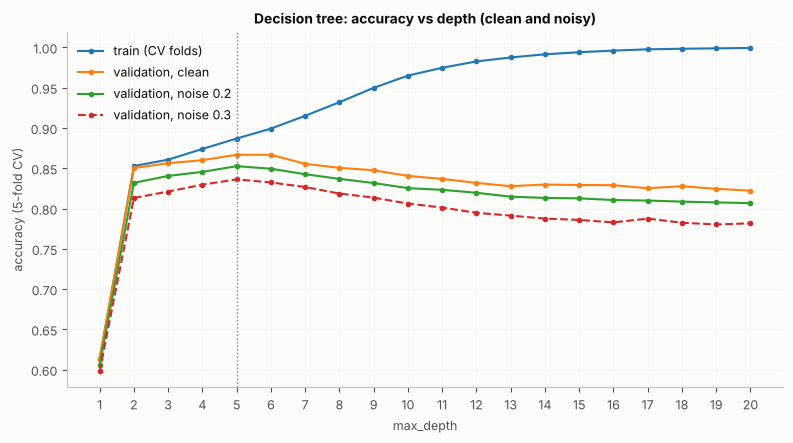

,max_depth,train,noise_0.0,noise_0.1,noise_0.2,noise_0.3,std_noise_0.2
0,1,0.6135,0.6135,0.6106,0.6061,0.5980,0.0080
1,2,0.8528,0.8502,0.8431,0.8319,0.8131,0.0043
2,3,0.8607,0.8563,0.8518,0.8405,0.8211,0.0061
3,4,0.8740,0.8600,0.8548,0.8455,0.8296,0.0068
4,5,0.8869,0.8668,0.8627,0.8526,0.8362,0.0045
5,6,0.8992,0.8667,0.8606,0.8494,0.8324,0.0030
6,7,0.9151,0.8555,0.8520,0.8426,0.8267,0.0086
7,8,0.9320,0.8505,0.8470,0.8368,0.8186,0.0050
8,9,0.9498,0.8475,0.8433,0.8317,0.8135,0.0086
9,10,0.9650,0.8405,0.8364,0.8253,0.8062,0.0094


In [37]:
import matplotlib.pyplot as plt

depth_rows = []
for d in range(1, 21):
    s = cv_noisy_score(DecisionTreeClassifier(max_depth=d, random_state=SEED))
    depth_rows.append({"max_depth": d, **s})
depth_curve = pd.DataFrame(depth_rows)
depth_curve.to_csv(OUT / "depth_curve.csv", index=False)

# Best depth on the noisy score, then the one-SE rule: simplest depth within 1 std of the best
best = depth_curve.loc[depth_curve["noise_0.2"].idxmax()]
threshold = best["noise_0.2"] - best["std_noise_0.2"]
one_se_depth = int(depth_curve.loc[depth_curve["noise_0.2"] >= threshold, "max_depth"].min())
best_clean = depth_curve.loc[depth_curve["noise_0.0"].idxmax()]

print(f"Best depth on CLEAN CV : {int(best_clean['max_depth'])}  (clean acc {best_clean['noise_0.0']:.4f})")
print(f"Best depth on NOISY 0.2: {int(best['max_depth'])}  (noisy acc {best['noise_0.2']:.4f} ± {best['std_noise_0.2']:.4f})")
print(f"One-SE rule depth      : {one_se_depth}  (simplest depth with noisy acc >= {threshold:.4f})")

log_result(f"depth curve: best max_depth={int(best['max_depth'])}",
           {k: best[k] for k in best.index if k != "max_depth"}, notes="Step 3, best on noise_0.2")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(depth_curve["max_depth"], depth_curve["train"], marker="o", ms=3, label="train (CV folds)")
ax.plot(depth_curve["max_depth"], depth_curve["noise_0.0"], marker="o", ms=3, label="validation, clean")
ax.plot(depth_curve["max_depth"], depth_curve["noise_0.2"], marker="o", ms=3, label="validation, noise 0.2")
ax.plot(depth_curve["max_depth"], depth_curve["noise_0.3"], marker="o", ms=3, linestyle="--", label="validation, noise 0.3")
ax.axvline(best["max_depth"], color="grey", linestyle=":", linewidth=1)
ax.set_xlabel("max_depth")
ax.set_ylabel("accuracy (5-fold CV)")
ax.set_title("Decision tree: accuracy vs depth (clean and noisy)")
ax.set_xticks(range(1, 21))
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(OUT / "depth_curve.png", dpi=150)
plt.show()

depth_curve[["max_depth", "train", "noise_0.0", "noise_0.1", "noise_0.2", "noise_0.3", "std_noise_0.2"]]

**Observation (Step 3):** Training accuracy rises steadily with depth (61% → 99.9%), but validation accuracy peaks at **max_depth = 5** (86.7% clean, 85.3% at noise 0.2, 83.6% at noise 0.3) and then declines — the classic bias–variance trade-off. A depth-1 stump reaches only 61% because its 2 leaves can predict at most 2 of the 3 classes. Deeper trees also lose more under noise (clean → noise 0.3: −3.1 points at depth 5 vs −4.5 at depth 18). The best depth is the same for clean and noisy data, and the one-SE rule also selects depth 5.

**Decision:** Depth 5 is the starting point for Step 4; tune max_depth 4–7 together with min_samples_leaf, criterion and pruning.

## Step 4 — Hyperparameter tuning
**4a. Grid search** over `max_depth` (4–8), `min_samples_leaf` (1, 5, 10, 20, 40, 80) and `criterion` (gini, entropy) = 60 combinations, each scored by 5-fold CV accuracy at noise 0.2. From all settings within one std of the best, we pick the simplest (one-SE rule).

**4b. Cost-complexity pruning**: on the chosen tree, try ~15 values of `ccp_alpha` (larger alpha = more branches cut). Keep the alpha with the best noisy score; on ties, the smaller tree.

In [38]:
from sklearn.tree import DecisionTreeClassifier
import itertools, time

# ---- 4a. Grid search, scored by 5-fold CV accuracy at noise 0.2 ----------------
grid = {
    "max_depth": [4, 5, 6, 7, 8],
    "min_samples_leaf": [1, 5, 10, 20, 40, 80],
    "criterion": ["gini", "entropy"],
}
t0 = time.time()
grid_rows = []
for depth, leaf, crit in itertools.product(grid["max_depth"], grid["min_samples_leaf"], grid["criterion"]):
    model = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=leaf, criterion=crit, random_state=SEED)
    grid_rows.append({"max_depth": depth, "min_samples_leaf": leaf, "criterion": crit, **cv_noisy_score(model)})
grid_results = pd.DataFrame(grid_rows).sort_values("noise_0.2", ascending=False).reset_index(drop=True)
grid_results.to_csv(OUT / "grid_results.csv", index=False)
print(f"{len(grid_results)} combinations in {time.time() - t0:.0f}s")

# One-SE rule: among settings within 1 std of the best noisy score, take the simplest
# (smallest depth first, then the largest min_samples_leaf)
top = grid_results.iloc[0]
threshold = top["noise_0.2"] - top["std_noise_0.2"]
candidates = grid_results[grid_results["noise_0.2"] >= threshold]
chosen = candidates.sort_values(["max_depth", "min_samples_leaf"], ascending=[True, False]).iloc[0]
best_params = {"max_depth": int(chosen["max_depth"]), "min_samples_leaf": int(chosen["min_samples_leaf"]),
               "criterion": chosen["criterion"]}

print(f"Best by noisy score : depth={int(top['max_depth'])}, leaf={int(top['min_samples_leaf'])}, "
      f"{top['criterion']} -> noise_0.2 = {top['noise_0.2']:.4f} ± {top['std_noise_0.2']:.4f}")
print(f"One-SE choice       : {best_params} -> noise_0.2 = {chosen['noise_0.2']:.4f} "
      f"({len(candidates)} settings within 1 std)")
log_result(f"grid: {best_params}", {k: chosen[k] for k in ["train", "noise_0.0", "noise_0.1", "noise_0.2",
                                                         "noise_0.3", "std_noise_0.2"]},
           notes="Step 4a, one-SE choice")

# ---- 4b. Cost-complexity pruning on top of the chosen settings -----------------
base = DecisionTreeClassifier(**best_params, random_state=SEED).fit(X_train, y_train)
alphas = base.cost_complexity_pruning_path(X_train, y_train).ccp_alphas
alphas = np.unique(np.quantile(alphas[:-1], np.linspace(0, 1, 15)))   # ~15 candidate values, skip the root-only tree
prune_rows = []
for a in alphas:
    model = DecisionTreeClassifier(**best_params, ccp_alpha=a, random_state=SEED)
    leaves = model.fit(X_train, y_train).get_n_leaves()
    prune_rows.append({"ccp_alpha": a, "leaves": leaves, **cv_noisy_score(model)})
prune_results = pd.DataFrame(prune_rows)
prune_results.to_csv(OUT / "pruning_results.csv", index=False)

# Keep the alpha with the best noisy score; on near-ties (within 0.001) take the larger alpha (= smaller tree).
# (No second one-SE step here: applying it twice would let the score drift down.)
p_best = prune_results["noise_0.2"].max()
p_chosen = prune_results[prune_results["noise_0.2"] >= p_best - 0.001].sort_values("ccp_alpha", ascending=False).iloc[0]
best_alpha = float(p_chosen["ccp_alpha"])
print(f"\nPruning: alpha=0 -> {prune_results.iloc[0]['noise_0.2']:.4f} ({int(prune_results.iloc[0]['leaves'])} leaves) | "
      f"chosen alpha={best_alpha:.5f} -> {p_chosen['noise_0.2']:.4f} ({int(p_chosen['leaves'])} leaves)")
log_result(f"pruned: {best_params}, ccp_alpha={best_alpha:.5f}",
           {k: p_chosen[k] for k in ["train", "noise_0.0", "noise_0.1", "noise_0.2", "noise_0.3", "std_noise_0.2"]},
           notes="Step 4b, best alpha")

TUNED_PARAMS = {**best_params, "ccp_alpha": best_alpha}
print("\nTUNED_PARAMS =", TUNED_PARAMS)
display(grid_results.head(10)[["max_depth", "min_samples_leaf", "criterion", "train", "noise_0.0",
                               "noise_0.2", "noise_0.3", "std_noise_0.2"]])
display(prune_results[["ccp_alpha", "leaves", "train", "noise_0.0", "noise_0.2", "noise_0.3"]].round(5))

60 combinations in 27s
Best by noisy score : depth=7, leaf=40, entropy -> noise_0.2 = 0.8569 ± 0.0077
One-SE choice       : {'max_depth': 5, 'min_samples_leaf': 40, 'criterion': 'entropy'} -> noise_0.2 = 0.8524 (24 settings within 1 std)



Pruning: alpha=0 -> 0.8524 (26 leaves) | chosen alpha=0.00148 -> 0.8518 (25 leaves)

TUNED_PARAMS = {'max_depth': 5, 'min_samples_leaf': 40, 'criterion': 'entropy', 'ccp_alpha': 0.0014767352985509614}


,max_depth,min_samples_leaf,criterion,train,noise_0.0,noise_0.2,noise_0.3,std_noise_0.2
0,7,40,entropy,0.8841,0.8672,0.8569,0.8354,0.0077
1,6,40,entropy,0.8823,0.8668,0.8567,0.8358,0.0079
2,7,20,entropy,0.8927,0.8635,0.8559,0.8376,0.0034
3,8,40,entropy,0.8850,0.8662,0.8554,0.8343,0.0076
4,6,5,entropy,0.8904,0.8668,0.8548,0.8375,0.0046
5,6,1,entropy,0.8919,0.8665,0.8538,0.8367,0.0045
6,6,20,entropy,0.8863,0.8647,0.8536,0.8366,0.0075
7,5,20,entropy,0.8792,0.8627,0.8531,0.8352,0.0035
8,5,10,gini,0.8843,0.8665,0.8529,0.8358,0.0044
9,5,5,gini,0.8860,0.8662,0.8529,0.8371,0.0036


,ccp_alpha,leaves,train,noise_0.0,noise_0.2,noise_0.3
0,0.00000,26,0.8768,0.8613,0.8524,0.8328
1,0.00148,25,0.8765,0.8612,0.8518,0.8325
2,0.00254,23,0.8758,0.8605,0.8504,0.8316
3,0.00280,21,0.8749,0.8590,0.8493,0.8306
4,0.00348,20,0.8725,0.8582,0.8471,0.8286
5,0.00373,18,0.8725,0.8582,0.8471,0.8286
6,0.00528,16,0.8718,0.8588,0.8461,0.8276
7,0.00558,14,0.8704,0.8575,0.8444,0.8268
8,0.00674,13,0.8656,0.8563,0.8414,0.8231
9,0.00779,11,0.8635,0.8530,0.8387,0.8194


**Observation (Step 4):** The grid search (60 settings, 5-fold CV, noise 0.2) found its highest score with depth 7, min_samples_leaf 40, entropy: 85.7% ± 0.8%. However, 24 settings lie within one standard deviation of it, so they are statistically tied — the tree has reached a **plateau around 85.5%** on noisy data. Following the one-SE rule we choose the simplest: **max_depth = 5, min_samples_leaf = 40, criterion = entropy** — only 25 leaves (vs 519 for the unconstrained tree), with 86.1% clean and 85.2% noisy CV accuracy. Large leaves (40 rows) appear throughout the top settings: they stop the tree from learning rules for tiny groups, which noise easily breaks. Cost-complexity pruning did not help: the depth and leaf-size limits had already pruned the tree, and cutting further branches only lowered accuracy (9 leaves: 83.9%; 2 leaves: 78.2%).

**Decision:** Use the tuned tree (`TUNED_PARAMS`) as the reference for Step 5. Since hyperparameters have plateaued, further gains must come from the inputs and training data (feature averaging, noise augmentation).

## Step 5b — Feature averaging (noise cancellation)
Groups of strongly correlated features measure the same property (size, power, height, efficiency). Each gets its own random noise, so the **average of the standardised group** keeps the signal while part of the noise cancels out (k features → noise sd ÷ √k).
We compare three feature sets on the same small grid (depth 4–8 × min_samples_leaf 20/40/80, entropy):
- **original**: the 20 raw features
- **add**: 20 features + 4 group scores
- **replace**: group features replaced by their scores
Standardisation is learned inside each CV training fold (Pipeline), so there is no leakage.

In [39]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
import itertools, time

# Groups of strongly correlated features (EDA section 8) that measure the same underlying property
BLOCKS = {
    "size_score":       ["vehicle_weight_kg", "wheelbase_mm", "vehicle_length_mm", "vehicle_width_mm", "fuel_tank_capacity_l"],
    "power_score":      ["horsepower_hp", "torque_nm", "engine_displacement_l", "engine_cylinders", "tire_width_mm"],
    "height_score":     ["vehicle_height_mm", "ground_clearance_mm", "cargo_capacity_l"],
    "efficiency_score": ["city_fuel_efficiency_kmpl", "highway_fuel_efficiency_kmpl"],
}


class BlockAverager(BaseEstimator, TransformerMixin):
    """Adds the average of the standardised features in each block.
    mode="add": keep all 20 features + 4 scores; mode="replace": drop the block's features, keep the scores.
    Means/stds are learned in fit() on the training fold only (no leakage)."""

    def __init__(self, blocks=None, mode="add"):
        self.blocks = blocks
        self.mode = mode

    def fit(self, X, y=None):
        cols = [c for feats in self.blocks.values() for c in feats]
        self.mean_ = X[cols].mean()
        self.std_ = X[cols].std()
        return self

    def transform(self, X):
        Xt = X.copy()
        for name, feats in self.blocks.items():
            z = (X[feats] - self.mean_[feats]) / self.std_[feats]
            Xt[name] = z.mean(axis=1)
        if self.mode == "replace":
            Xt = Xt.drop(columns=[c for feats in self.blocks.values() for c in feats])
        return Xt


def tree_pipeline(features, **tree_params):
    tree = DecisionTreeClassifier(random_state=SEED, **tree_params)
    if features == "original":
        return tree
    return Pipeline([("blocks", BlockAverager(BLOCKS, mode=features)), ("tree", tree)])


# Same small grid for every feature set, so the comparison is fair
mini_grid = list(itertools.product([4, 5, 6, 7, 8], [20, 40, 80]))
fe_rows = []
t0 = time.time()
for features in ["original", "add", "replace"]:
    for depth, leaf in mini_grid:
        model = tree_pipeline(features, max_depth=depth, min_samples_leaf=leaf, criterion="entropy")
        fe_rows.append({"features": features, "max_depth": depth, "min_samples_leaf": leaf, **cv_noisy_score(model)})
fe_results = pd.DataFrame(fe_rows)
fe_results.to_csv(OUT / "feature_averaging_results.csv", index=False)
print(f"{len(fe_results)} runs in {time.time() - t0:.0f}s\n")

# Best setting per feature set, then check it under engine-only noise too
summary = []
for features, grp in fe_results.groupby("features", sort=False):
    b = grp.loc[grp["noise_0.2"].idxmax()]
    model = tree_pipeline(features, max_depth=int(b["max_depth"]), min_samples_leaf=int(b["min_samples_leaf"]),
                          criterion="entropy")
    eng = cv_noisy_score(model, mode="engine")
    summary.append({"features": features, "max_depth": int(b["max_depth"]), "min_samples_leaf": int(b["min_samples_leaf"]),
                    "clean": b["noise_0.0"], "noisy_0.2": b["noise_0.2"], "noisy_0.3": b["noise_0.3"],
                    "std_0.2": b["std_noise_0.2"], "engine_noisy_0.3": eng["noise_0.3"]})
    log_result(f"5b features={features}: depth={int(b['max_depth'])}, leaf={int(b['min_samples_leaf'])}",
               {k: b[k] for k in ["train", "noise_0.0", "noise_0.1", "noise_0.2", "noise_0.3", "std_noise_0.2"]},
               notes="Step 5b feature averaging, best of mini grid")
fe_summary = pd.DataFrame(summary)
display(fe_summary)

45 runs in 39s



,features,max_depth,min_samples_leaf,clean,noisy_0.2,noisy_0.3,std_0.2,engine_noisy_0.3
0,original,7,40,0.8672,0.8569,0.8354,0.0077,0.8575
1,add,7,40,0.8667,0.8561,0.8362,0.0045,0.8574
2,replace,7,40,0.8657,0.8613,0.8506,0.0048,0.8588


**Observation (Step 5b):** Replacing each group of correlated features by the average of its standardised members ("replace", 9 inputs) keeps clean accuracy (86.6% vs 86.7%) but loses much less under noise: 86.1% at noise 0.2 and **85.1% at noise 0.3**, versus 85.7% and 83.5% for the original 20 features (clean → 0.3 drop: −1.5 vs −3.2 points). Under engine-only noise all variants are tied (~85.8%). Adding the scores while keeping the originals ("add") gave no gain — the tree keeps splitting on the noisy originals.

**Decision:** Use the "replace" feature set (4 group scores + 5 ungrouped features): never worse than the original features, clearly more robust if the test noise is larger or affects more features than estimated, and simpler (9 inputs).

## Step 5a — Noise augmentation
Each CV training fold is extended with 2 noisy copies of itself (noise level 0.1 or 0.2), so the tree learns split thresholds that are stable under small measurement changes. Validation folds are never augmented. Uses the "replace" feature set from Step 5b. Grid: max_depth 5–8 × min_samples_leaf 40/80/160 (larger leaves, because augmented data has 3× more rows).

In [40]:
FEATURE_SET = "replace"          # chosen in Step 5b

# augment = number of extra noisy copies of the training fold, aug_level = their noise level
aug_configs = [(0, 0.0), (2, 0.1), (2, 0.2)]
aug_grid = list(itertools.product([5, 6, 7, 8], [40, 80, 160]))   # bigger leaves: augmented data has 3x more rows

aug_rows = []
t0 = time.time()
for n_copies, level in aug_configs:
    for depth, leaf in aug_grid:
        model = tree_pipeline(FEATURE_SET, max_depth=depth, min_samples_leaf=leaf, criterion="entropy")
        s = cv_noisy_score(model, augment=n_copies, aug_level=level)
        aug_rows.append({"augment": n_copies, "aug_level": level, "max_depth": depth, "min_samples_leaf": leaf, **s})
aug_results = pd.DataFrame(aug_rows)
aug_results.to_csv(OUT / "augmentation_results.csv", index=False)
print(f"{len(aug_results)} runs in {time.time() - t0:.0f}s\n")

# Best setting per augmentation config, plus an engine-only noise check
summary = []
for (n_copies, level), grp in aug_results.groupby(["augment", "aug_level"], sort=False):
    b = grp.loc[grp["noise_0.2"].idxmax()]
    model = tree_pipeline(FEATURE_SET, max_depth=int(b["max_depth"]), min_samples_leaf=int(b["min_samples_leaf"]),
                          criterion="entropy")
    eng = cv_noisy_score(model, mode="engine", augment=n_copies, aug_level=level)
    summary.append({"augment": f"{n_copies} copies @ {level}" if n_copies else "none",
                    "max_depth": int(b["max_depth"]), "min_samples_leaf": int(b["min_samples_leaf"]),
                    "train": b["train"], "clean": b["noise_0.0"], "noisy_0.2": b["noise_0.2"],
                    "noisy_0.3": b["noise_0.3"], "std_0.2": b["std_noise_0.2"], "engine_noisy_0.3": eng["noise_0.3"]})
    log_result(f"5a replace + augment={n_copies}@{level}: depth={int(b['max_depth'])}, leaf={int(b['min_samples_leaf'])}",
               {k: b[k] for k in ["train", "noise_0.0", "noise_0.1", "noise_0.2", "noise_0.3", "std_noise_0.2"]},
               notes="Step 5a noise augmentation, best of grid")
aug_summary = pd.DataFrame(summary)
display(aug_summary)

36 runs in 53s



,augment,max_depth,min_samples_leaf,train,clean,noisy_0.2,noisy_0.3,std_0.2,engine_noisy_0.3
0,none,7,40,0.8840,0.8657,0.8613,0.8506,0.0048,0.8588
1,2 copies @ 0.1,8,80,0.8865,0.8688,0.8606,0.8489,0.0085,0.8619
2,2 copies @ 0.2,7,40,0.8890,0.8685,0.8631,0.8536,0.0050,0.8650


**Observation (Step 5a):** Training on the "replace" features plus 2 noisy copies at noise level 0.2 (depth 7, min_samples_leaf 40) is slightly better on every measure than no augmentation: clean 86.9% vs 86.6%, noise 0.2 86.3% vs 86.1%, noise 0.3 85.4% vs 85.1%, engine-only noise 0.3 86.5% vs 85.9%. The gains (0.2–0.6 points) are consistent in direction but within the CV standard deviation (~0.5). Copies at noise 0.1 gave no clear gain.

**Decision:** Carry both "replace + augmentation (2 copies @ 0.2)" and "replace, no augmentation" into Step 6 and decide with repeated CV seeds.

## Step 6 — Final recipe (incl. Step 5d: test-time augmentation)
Three candidates, all using the "replace" features and the same tree (depth 7, min_samples_leaf 40, entropy):
- **A**: no augmentation
- **B**: + noise augmentation (2 copies @ 0.2)
- **C**: + test-time augmentation (TTA): predict on 15 slightly noisy copies (noise 0.1) of each row and take the majority vote

Each is evaluated with **3 different CV splits** (seeds 42, 7, 123) under all-feature noise and engine-only noise. Robust score = mean of noise 0.2, noise 0.3 and engine-only noise 0.3. We choose the best robust score, but prefer a simpler candidate if it is within 0.2 points.

In [41]:
# Final candidates (all: "replace" features, entropy, depth 7, min_samples_leaf 40), from simplest to most complex
CANDIDATES = {
    "A: replace":                  dict(augment=0, aug_level=0.0, tta=0),
    "B: replace + augment":        dict(augment=2, aug_level=0.2, tta=0),
    "C: replace + augment + TTA":  dict(augment=2, aug_level=0.2, tta=15, tta_level=0.1),
}
FINAL_TREE = dict(max_depth=7, min_samples_leaf=40, criterion="entropy")
CV_SEEDS = [42, 7, 123]   # 3 different fold splits -> is a gain real or luck?

rows = []
t0 = time.time()
for name, opts in CANDIDATES.items():
    model = tree_pipeline("replace", **FINAL_TREE)
    for seed in CV_SEEDS:
        s_all = cv_noisy_score(model, cv_seed=seed, mode="all", **opts)
        s_eng = cv_noisy_score(model, cv_seed=seed, mode="engine", **opts)
        rows.append({"candidate": name, "cv_seed": seed, "clean": s_all["noise_0.0"], "noisy_0.2": s_all["noise_0.2"],
                     "noisy_0.3": s_all["noise_0.3"], "engine_0.3": s_eng["noise_0.3"]})
final_runs = pd.DataFrame(rows)
final_runs.to_csv(OUT / "final_candidates.csv", index=False)
print(f"{len(final_runs)} runs in {time.time() - t0:.0f}s\n")

# Mean ± std over the 3 seeds
metrics = ["clean", "noisy_0.2", "noisy_0.3", "engine_0.3"]
cand_summary = final_runs.groupby("candidate", sort=False)[metrics].agg(["mean", "std"]).round(4)
# One robustness score = average of the three noisy measures
cand_summary[("robust", "mean")] = final_runs.groupby("candidate", sort=False)[["noisy_0.2", "noisy_0.3", "engine_0.3"]] \
    .mean().mean(axis=1).round(4)
display(cand_summary)

# Choose: best robust score; if a simpler candidate is within 0.002 (0.2 points), prefer the simpler one
robust = cand_summary[("robust", "mean")]
best_score = robust.max()
FINAL_CANDIDATE = next(name for name in CANDIDATES if robust[name] >= best_score - 0.002)
FINAL_OPTS = CANDIDATES[FINAL_CANDIDATE]
print("\nChosen final recipe:", FINAL_CANDIDATE, "| tree:", FINAL_TREE, "| options:", FINAL_OPTS)

for name in CANDIDATES:
    m = final_runs[final_runs["candidate"] == name][metrics].mean()
    log_result(f"6 final candidate {name}", {"noise_0.0": round(m["clean"], 4), "noise_0.2": round(m["noisy_0.2"], 4),
                                             "noise_0.3": round(m["noisy_0.3"], 4)},
               notes=f"Step 6, mean of 3 CV seeds; engine_0.3={m['engine_0.3']:.4f}")

9 runs in 92s



clean         noisy_0.2         noisy_0.3         engine_0.3          robust
                              mean     std      mean     std      mean     std       mean     std    mean
candidate                                                                                                
A: replace                  0.8611  0.0040    0.8558  0.0048    0.8462  0.0039     0.8557  0.0031  0.8526
B: replace + augment        0.8666  0.0054    0.8594  0.0045    0.8501  0.0038     0.8634  0.0040  0.8576
C: replace + augment + TTA  0.8674  0.0061    0.8607  0.0048    0.8517  0.0044     0.8651  0.0042  0.8591


Chosen final recipe: B: replace + augment | tree: {'max_depth': 7, 'min_samples_leaf': 40, 'criterion': 'entropy'} | options: {'augment': 2, 'aug_level': 0.2, 'tta': 0}


**Observation (Step 6):** Averaged over 3 different CV splits, noise augmentation (B) beats the plain "replace" tree (A) on every measure: clean 86.7% vs 86.1%, noise 0.2 85.9% vs 85.6%, noise 0.3 85.0% vs 84.6%, engine-only noise 0.3 86.3% vs 85.6% (robust score 85.76 vs 85.26) — the gain holds across splits, so it is real. Test-time augmentation (C) adds only +0.15 to the robust score while making prediction 15× slower.

**Decision — final recipe (B):** decision tree (max_depth 7, min_samples_leaf 40, entropy) on the 9 "replace" inputs, trained with 2 noisy copies of the training data (noise 0.2). No TTA.

## Step 7 — Final evaluation on the 1,500 validation rows (used once)
Three models are trained on the 6,000 training rows and tested once on the untouched validation rows — clean, with noise 0.1 / 0.2 / 0.3 on all features (5 noise draws each), and noise 0.3 on engine features only:
1. unconstrained tree (Step 2), 2. tuned tree on 20 features (Step 4), 3. **final model** (Step 6).
Then: confusion matrices, per-class precision/recall/F1, and which classes get confused.

,model,clean,noisy_0.1,noisy_0.2,noisy_0.3,engine_0.3
0,unconstrained tree (Step 2),0.8140,0.8079,0.7920,0.7657,0.8012
1,"tuned tree, 20 features (Step 4)",0.8320,0.8360,0.8321,0.8187,0.8247
2,FINAL: replace + augment (Step 6),0.8487,0.8437,0.8412,0.8325,0.8443


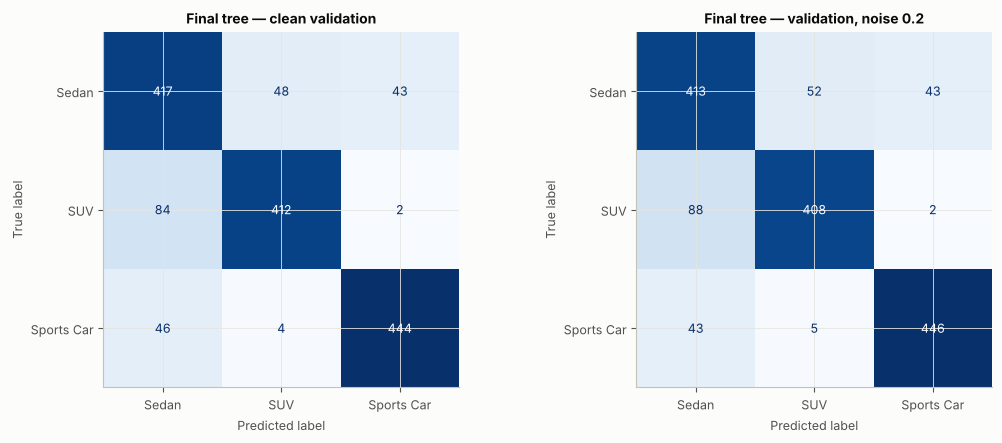

Classification report — validation, noise 0.2:

              precision    recall  f1-score   support

       Sedan      0.759     0.813     0.785       508
         SUV      0.877     0.819     0.847       498
  Sports Car      0.908     0.903     0.906       494

    accuracy                          0.845      1500
   macro avg      0.848     0.845     0.846      1500
weighted avg      0.848     0.845     0.845      1500

Errors: 233 of 1500 (15.5%)
true        predicted 
SUV         Sedan         88
Sedan       SUV           52
            Sports Car    43
Sports Car  Sedan         43
            SUV            5
SUV         Sports Car     2


In [42]:
import joblib
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

FINAL_AUG = dict(n_copies=2, level=0.2)   # recipe B from Step 6


def fit_final(model, X, y, augment=True):
    """Fit on X, y (+ 2 noisy copies @ 0.2 if augment)."""
    if augment:
        X, y = make_augmented(X, y, FINAL_AUG["n_copies"], FINAL_AUG["level"], seed=2026)
    return clone(model).fit(X, y)


def val_scores(model, n_draws=5):
    """Accuracy on the 1,500 validation rows: clean, noise 0.1/0.2/0.3 (all features), noise 0.3 (engine only)."""
    out = {"clean": (model.predict(X_val) == y_val.values).mean()}
    for level in [0.1, 0.2, 0.3]:
        out[f"noisy_{level}"] = np.mean([(model.predict(add_noise(X_val, level, seed=900 + d)) == y_val.values).mean()
                                         for d in range(n_draws)])
    out["engine_0.3"] = np.mean([(model.predict(add_noise(X_val, 0.3, seed=900 + d, features=ENGINE_FEATURES))
                                  == y_val.values).mean() for d in range(n_draws)])
    return {k: round(float(v), 4) for k, v in out.items()}


# Three models trained on the 6,000 training rows, tested ONCE on the 1,500 validation rows
models = {
    "unconstrained tree (Step 2)": (DecisionTreeClassifier(random_state=SEED), False),
    "tuned tree, 20 features (Step 4)": (DecisionTreeClassifier(max_depth=5, min_samples_leaf=40, criterion="entropy",
                                                                random_state=SEED), False),
    "FINAL: replace + augment (Step 6)": (tree_pipeline("replace", **FINAL_TREE), True),
}
val_rows, fitted = [], {}
for name, (model, aug) in models.items():
    fitted[name] = fit_final(model, X_train, y_train, augment=aug)
    val_rows.append({"model": name, **val_scores(fitted[name])})
val_results = pd.DataFrame(val_rows)
val_results.to_csv(OUT / "validation_results.csv", index=False)
display(val_results)

final_model = fitted["FINAL: replace + augment (Step 6)"]
joblib.dump(final_model, OUT / "final_tree_trained_on_6000.joblib")

# Confusion matrices: clean and noise 0.2 validation data
labels = [CLASS_NAMES[c] for c in sorted(CLASS_NAMES)]
X_val_noisy = add_noise(X_val, 0.2, seed=900)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (title, Xv) in zip(axes, [("clean validation", X_val), ("validation, noise 0.2", X_val_noisy)]):
    cm = confusion_matrix(y_val, final_model.predict(Xv))
    ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(f"Final tree — {title}")
fig.tight_layout()
fig.savefig(OUT / "confusion_matrices.png", dpi=150)
plt.show()

print("Classification report — validation, noise 0.2:\n")
print(classification_report(y_val, final_model.predict(X_val_noisy), target_names=labels, digits=3))

# Error analysis: which class pairs are confused (noise 0.2)
pred = final_model.predict(X_val_noisy)
errors = pd.DataFrame({"true": y_val.map(CLASS_NAMES), "predicted": pd.Series(pred).map(CLASS_NAMES)})
errors = errors[errors["true"] != errors["predicted"]]
print(f"Errors: {len(errors)} of {len(y_val)} ({len(errors) / len(y_val):.1%})")
print(errors.value_counts().rename("count").to_string())

**Observation (Step 7):** On the 1,500 untouched validation rows the final model scores **84.9% clean, 84.1% at noise 0.2, 83.2% at noise 0.3 and 84.4% with engine-only noise**, beating the tuned 20-feature tree (83.2 / 83.2 / 81.9 / 82.5) and the unconstrained tree (81.4 / 79.2 / 76.6 / 80.1). The advantage grows with noise: +3.5 points clean, +4.9 at noise 0.2, +6.7 at noise 0.3 over the unconstrained tree. Validation accuracy is ~1.8 points below CV, as expected after choosing the best of many settings (selection optimism) and given ±0.9% sampling error on 1,500 rows; the ranking of the models is unchanged.
Of the 233 errors at noise 0.2, 226 (97%) involve Sedan (largest: SUV → Sedan 88, Sedan → SUV 52); SUV and Sports Car are almost never confused (7). Sports Car is the easiest class (F1 0.906), Sedan the hardest (F1 0.785) — consistent with the EDA, where sedans lie between the other two classes.

## Step 8 — Interpretation
1. The first 3 levels of the final tree (diagram + text rules).
2. **Impurity importance** of the 9 inputs the tree uses.
3. **Permutation importance** of the 20 raw features on noisy validation data: how much accuracy drops when one feature is randomly shuffled (more reliable than impurity importance).

Tree: depth 7 | leaves 88 | inputs: ['turning_radius_m', 'acceleration_0_100_kmh_s', 'braking_distance_m', 'drag_coefficient', 'battery_capacity_kwh', 'size_score', 'power_score', 'height_score', 'efficiency_score'] 



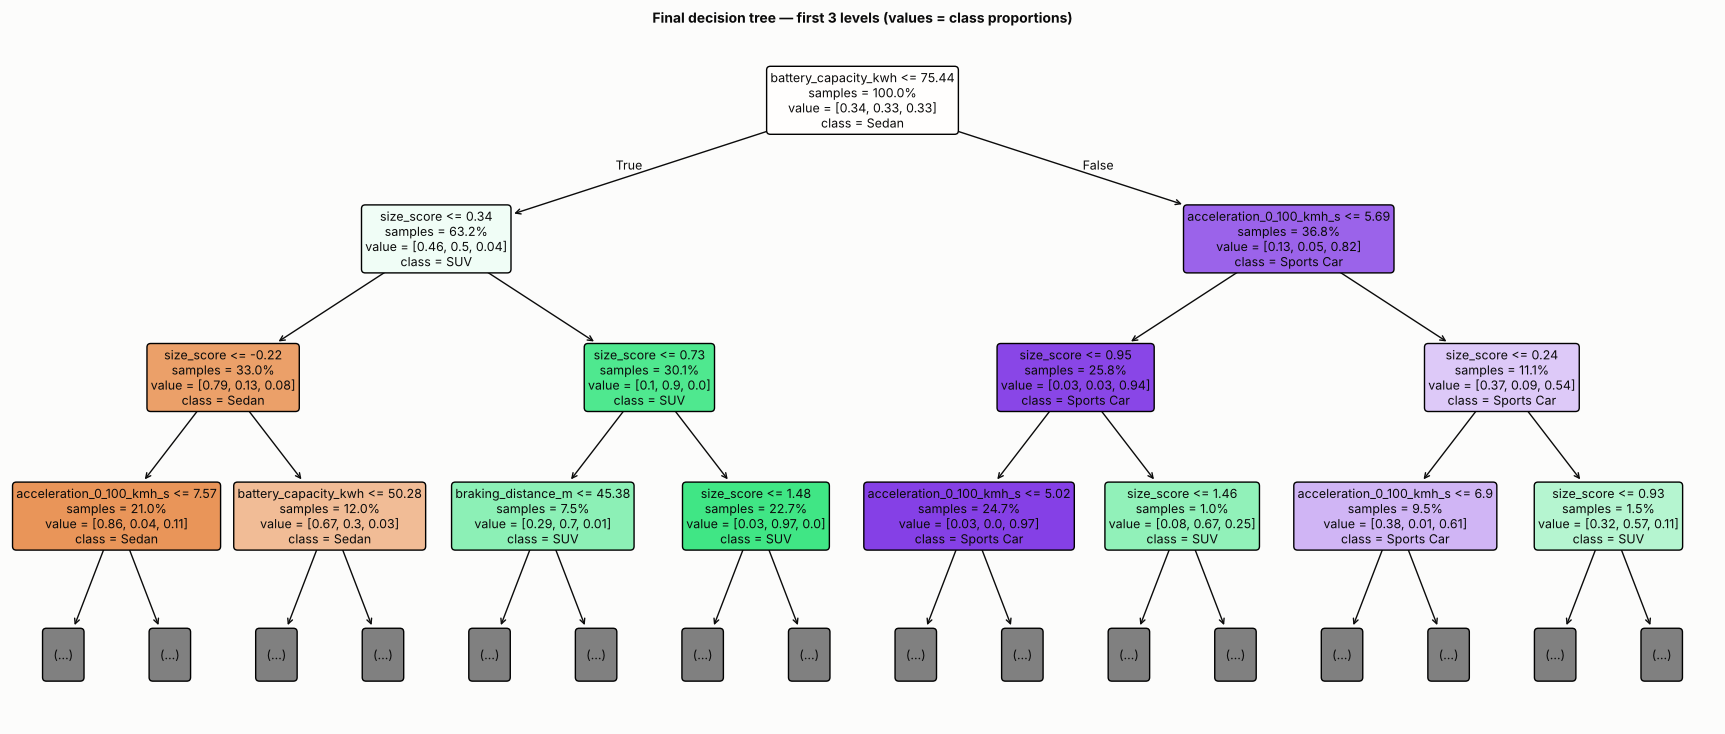

|--- battery_capacity_kwh <= 75.44
|   |--- size_score <= 0.34
|   |   |--- size_score <= -0.22
|   |   |   |--- acceleration_0_100_kmh_s <= 7.57
|   |   |   |   |--- truncated branch of depth 4
|   |   |   |--- acceleration_0_100_kmh_s >  7.57
|   |   |   |   |--- truncated branch of depth 4
|   |   |--- size_score >  -0.22
|   |   |   |--- battery_capacity_kwh <= 50.28
|   |   |   |   |--- truncated branch of depth 4
|   |   |   |--- battery_capacity_kwh >  50.28
|   |   |   |   |--- truncated branch of depth 4
|   |--- size_score >  0.34
|   |   |--- size_score <= 0.73
|   |   |   |--- braking_distance_m <= 45.38
|   |   |   |   |--- truncated branch of depth 4
|   |   |   |--- braking_distance_m >  45.38
|   |   |   |   |--- truncated branch of depth 4
|   |   |--- size_score >  0.73
|   |   |   |--- size_score <= 1.48
|   |   |   |   |--- truncated branch of depth 4
|   |   |   |--- size_score >  1.48
|   |   |   |   |--- truncated branch of depth 3
|--- battery_capacity_kwh >  75

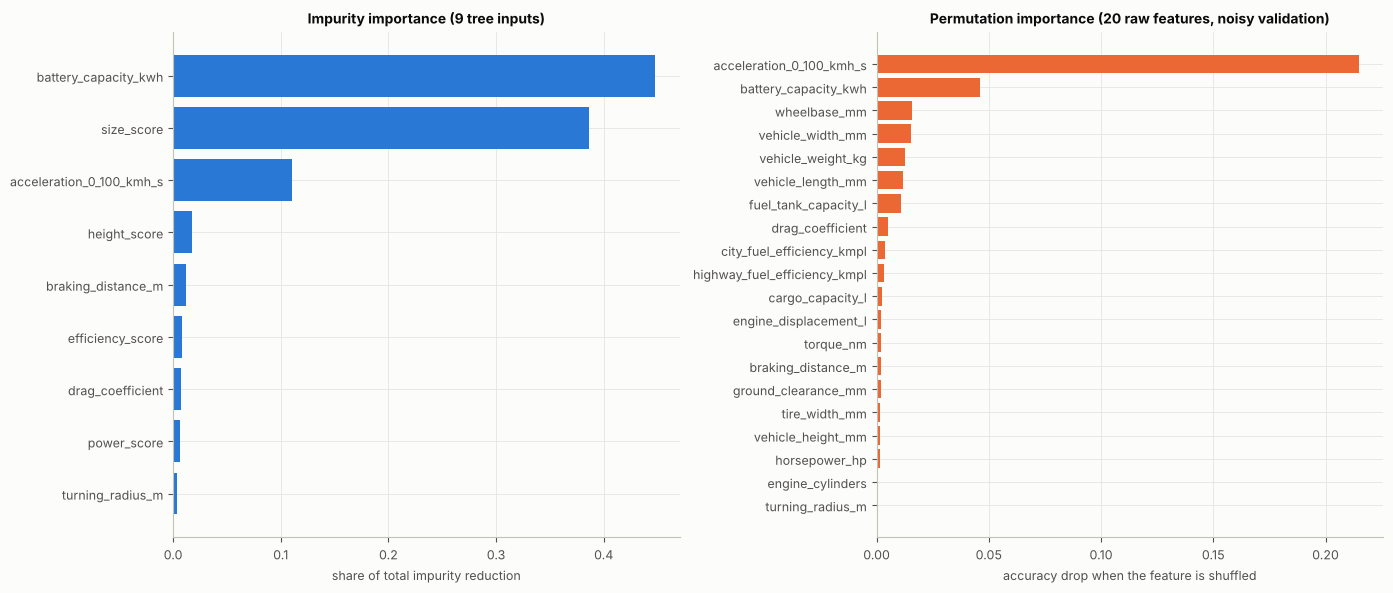

Top 5 raw features by permutation importance (accuracy drop):
acceleration_0_100_kmh_s    0.2149
battery_capacity_kwh        0.0459
wheelbase_mm                0.0157
vehicle_width_mm            0.0151
vehicle_weight_kg           0.0125


In [43]:
from sklearn.tree import plot_tree, export_text
from sklearn.inspection import permutation_importance

tree = final_model.named_steps["tree"]
blocks = final_model.named_steps["blocks"]
INPUT_NAMES = list(blocks.transform(X_val.head()).columns)     # the 9 inputs the tree actually sees
print("Tree: depth", tree.get_depth(), "| leaves", tree.get_n_leaves(), "| inputs:", INPUT_NAMES, "\n")

# 1) The top of the tree (first 3 levels)
fig, ax = plt.subplots(figsize=(22, 9))
plot_tree(tree, max_depth=3, feature_names=INPUT_NAMES, class_names=labels, filled=True, rounded=True,
          impurity=False, proportion=True, precision=2, fontsize=9, ax=ax)
ax.set_title("Final decision tree — first 3 levels (values = class proportions)")
fig.savefig(OUT / "tree_top3_levels.png", dpi=150, bbox_inches="tight")
plt.show()
print(export_text(tree, feature_names=INPUT_NAMES, max_depth=3, decimals=2))

# 2) Impurity-based importance of the 9 inputs
imp = pd.Series(tree.feature_importances_, index=INPUT_NAMES).sort_values()

# 3) Permutation importance of the 20 raw features on NOISY validation data (more reliable)
perm = permutation_importance(final_model, X_val_noisy, y_val, n_repeats=10, random_state=SEED, scoring="accuracy")
perm_imp = pd.Series(perm.importances_mean, index=X_val.columns).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].barh(imp.index, imp.values, color="#2a78d6")
axes[0].set_title("Impurity importance (9 tree inputs)")
axes[0].set_xlabel("share of total impurity reduction")
axes[1].barh(perm_imp.index, perm_imp.values, color="#eb6834")
axes[1].set_title("Permutation importance (20 raw features, noisy validation)")
axes[1].set_xlabel("accuracy drop when the feature is shuffled")
fig.tight_layout()
fig.savefig(OUT / "feature_importance.png", dpi=150)
plt.show()

print("Top 5 raw features by permutation importance (accuracy drop):")
print(perm_imp.sort_values(ascending=False).head(5).round(4).to_string())

**Observation (Step 8):** The final tree relies mainly on three inputs: **battery capacity** (45% of impurity reduction), **size_score** (39%) and **acceleration 0–100** (11%) — 95% together. Permutation importance on noisy validation data shows that shuffling acceleration costs **21.5 accuracy points** (it is the key sports-car signal), battery capacity 4.6 points, and each size feature only 1–1.6 points, because the tree uses their average — the other four still carry the signal (this redundancy is what makes the model robust). The engine features that carry extra noise in the test data (horsepower, torque, cylinders, displacement) have almost no importance, which explains the model's small loss under engine-only noise. Braking distance matters little despite being the best single feature in the EDA, because it is strongly correlated with size, which size_score already captures.

## Step 9 — Decision-tree submission file
The final recipe (Step 6) retrained on all 7,500 rows and applied to the test set. This file was my decision-tree Kaggle submission (public score **86.8%**).

In [44]:
import joblib

# Final model on ALL 7,500 cleaned rows -> predict the Kaggle test file -> submission CSV
FINAL_TREE = dict(max_depth=7, min_samples_leaf=40, criterion="entropy")
X_all = train_clean[FEATURE_COLUMNS].reset_index(drop=True)
y_all = train_clean[TARGET_COLUMN].reset_index(drop=True)
X_aug, y_aug = make_augmented(X_all, y_all, n_copies=2, level=0.2, seed=2026)
submission_model = tree_pipeline("replace", **FINAL_TREE).fit(X_aug, y_aug)

test = pd.read_csv(DATA_DIR / "vehicle_test.csv")
pred = submission_model.predict(test[FEATURE_COLUMNS])
submission = pd.DataFrame({ID_COLUMN: test[ID_COLUMN], TARGET_COLUMN: pred.astype(int)})

# Sanity checks before uploading
sample = pd.read_csv(DATA_DIR / "vehicle_sample_submission.csv")
assert list(submission.columns) == list(sample.columns), "column names/order differ from sample submission"
assert len(submission) == len(sample) == len(test), "row count mismatch"
assert set(submission[ID_COLUMN]) == set(sample[ID_COLUMN]), "vehicle_id values differ from sample submission"
assert submission[TARGET_COLUMN].isin([0, 1, 2]).all()

sub_path = OUT / "submission_decision_tree.csv"
submission.to_csv(sub_path, index=False)
joblib.dump(submission_model, OUT / "final_tree_trained_on_7500.joblib")
print("Saved:", sub_path, submission.shape)
print("Predicted class mix:\n", submission[TARGET_COLUMN].map(CLASS_NAMES).value_counts(normalize=True).round(3).to_string())

Saved: /home/claude/vv2/final/data/final_outputs/decision_tree/submission_decision_tree.csv (2500, 2)
Predicted class mix:
 vehicle_class
SUV           0.344
Sports Car    0.342
Sedan         0.314


# Part 4 — Final model: Logistic Regression + XGBoost (52 : 48 blend)

**Submission file:** `blend_logit_xgb_52_48.csv`  
**Based on:** the team's winning recipe (developed with my teammate) (LR + XGBoost, public Kaggle score **0.90700** with a 50:50 blend)  
**Task:** Multiclass classification into three synthetic vehicle classes.

This notebook follows the team's final-inference recipe exactly, with **one change**: the blend gives **52% weight to Logistic Regression and 48% to XGBoost** (instead of 50:50). Data, preprocessing, both models and all hyperparameters are unchanged. It uses **no neural networks**.

**Library versions are pinned** (`scikit-learn 1.9.1`, `xgboost 3.4.1`) in the setup cell (Part 0): XGBoost builds slightly different trees in different versions, and pinning makes the submission file reproducible row for row. The last cell checks that the file matches the submitted one.

### Rules applied
- Training-only preprocessing: `StandardScaler` is fitted to labeled training records only.
- Duplicate vehicle-feature rows are dropped before fitting, preserving original order.
- `vehicle_id` is excluded from model inputs.
- In this part the test set is used only for prediction and submission formatting; no test statistic enters the model (the train-vs-test comparison in Part 1 is diagnostic only).
- Ensemble weights and all hyperparameters are fixed **before** test inference.
- The optional cross-validation below is for documentation and **does not** change the locked model.

In [45]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score
from xgboost import XGBClassifier

TRAIN_FILENAME, TEST_FILENAME, SAMPLE_FILENAME = TRAIN_PATH.name, TEST_PATH.name, SAMPLE_PATH.name
OUTPUT_FILENAME = "blend_logit_xgb_52_48.csv"
W_LOGIT, W_XGB = 0.52, 0.48   # the one change: 52:48 instead of 50:50
print("Blend weights: LR", W_LOGIT, "| XGBoost", W_XGB)

Blend weights: LR 0.52 | XGBoost 0.48


## 4.1 Training-only inspection and leakage checks

Do not open or analyze the test features in this section. The official evaluation metric is **classification accuracy**.

In [46]:
train = pd.read_csv(DATA_DIR / TRAIN_FILENAME)
TARGET = "vehicle_class"
ID = "vehicle_id"
feature_columns = [c for c in train.columns if c not in (ID, TARGET)]

assert TARGET in train.columns and ID in train.columns
assert len(feature_columns) == 20, f"Expected 20 input features; found {len(feature_columns)}"
assert not train[feature_columns + [TARGET]].isnull().any().any(), "Missing train values: review preprocessing"
assert train[TARGET].nunique() == 3, "Expected 3 target classes"

print("Training records:", len(train))
print("Features:", len(feature_columns))
print("Class counts:", train[TARGET].value_counts().sort_index().to_dict())

# Duplicate-feature observations may never be split between CV training and validation.
conflicting = train.groupby(feature_columns, dropna=False)[TARGET].nunique()
assert conflicting.max() == 1, "Identical features have conflicting labels: manual audit required"
unique_train = train.drop_duplicates(subset=feature_columns).reset_index(drop=True)
X = unique_train[feature_columns]
y = unique_train[TARGET]
classes = np.sort(y.unique())

print("Unique feature records:", len(unique_train))
print("Duplicate-feature rows removed:", len(train) - len(unique_train))
print("Label classes:", classes.tolist())

Training records: 10000
Features: 20
Class counts: {0: 3389, 1: 3326, 2: 3285}
Unique feature records: 7500
Duplicate-feature rows removed: 2500
Label classes: [0, 1, 2]


## 4.2 Locked model recipes

These are the team's winning parameters. **No retuning is performed.** Only the blend weights change (52:48).

| Component | Parameters |
|---|---|
| Logistic Regression | `StandardScaler()`, `C=1`, `solver='lbfgs'`, `max_iter=1600` |
| XGBoost | `n_estimators=290`, `max_depth=5`, `learning_rate=0.042`, `min_child_weight=6` |
| XGBoost sampling | `subsample=0.8`, `colsample_bytree=0.8` |
| XGBoost regularization | `reg_alpha=0.4`, `reg_lambda=8` |
| XGBoost runtime | `tree_method='hist'`, `eval_metric='mlogloss'`, `n_jobs=1`, `random_state=42` |
| Ensemble (**change**) | **0.52 × Logistic predict_proba + 0.48 × XGBoost predict_proba** |

The **class with maximum blended probability** is the submitted label.

In [47]:
def build_logistic_regression():
    return make_pipeline(
        StandardScaler(),
        LogisticRegression(C=1.0, max_iter=1600, solver="lbfgs"),
    )


def build_xgboost():
    return XGBClassifier(
        n_estimators=290,
        max_depth=5,
        learning_rate=0.042,
        min_child_weight=6,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=8,
        reg_alpha=0.4,
        tree_method="hist",
        eval_metric="mlogloss",
        n_jobs=1,
        random_state=SEED,
    )


def blend_predict_proba(logit_model, xgb_model, X_new):
    """Return probabilities in the shared, numeric sorted class order."""
    logit_prob = logit_model.predict_proba(X_new)
    xgb_prob = xgb_model.predict_proba(X_new)
    np.testing.assert_array_equal(logit_model.classes_, xgb_model.classes_)
    return W_LOGIT * logit_prob + W_XGB * xgb_prob

## 4.3 Optional, training-only cross-validation

Five-fold stratified CV is **optional** and does not influence the locked hyperparameters or the 52:48 blend. Only deduplicated training examples are split, preventing exact-record leakage. Each fold trains its own scaler from the fold's training subset.

Toggle `RUN_CV` to `False` if you only need to recreate the Kaggle submission quickly. CV accuracy and the public Kaggle accuracy can differ because they are computed on different samples.

In [48]:
RUN_CV = True
cv_results = []
if RUN_CV:
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    oof_predictions = np.empty(len(y), dtype=classes.dtype)
    for fold_num, (tr_idx, val_idx) in enumerate(cv.split(X, y), start=1):
        X_tr, X_val = X.iloc[tr_idx], X.iloc[val_idx]
        y_tr, y_val = y.iloc[tr_idx], y.iloc[val_idx]
        logit = build_logistic_regression()
        xgb = build_xgboost()
        logit.fit(X_tr, y_tr)
        xgb.fit(X_tr, y_tr)
        probs = blend_predict_proba(logit, xgb, X_val)
        fold_pred = logit.classes_[np.argmax(probs, axis=1)]
        oof_predictions[val_idx] = fold_pred
        train_probs = blend_predict_proba(logit, xgb, X_tr)
        train_pred = logit.classes_[np.argmax(train_probs, axis=1)]
        fold_val_score = accuracy_score(y_val, fold_pred)
        fold_train_score = accuracy_score(y_tr, train_pred)
        cv_results.append({"fold": fold_num, "train_accuracy": fold_train_score,
                           "validation_accuracy": fold_val_score,
                           "gap_pp": 100 * (fold_train_score - fold_val_score)})
    cv_table = pd.DataFrame(cv_results)
    print(cv_table.to_string(index=False, float_format=lambda z: f"{z:.5f}"))
    print(f"Mean CV accuracy: {cv_table['validation_accuracy'].mean():.5f}")
    print(f"CV std (across folds): {cv_table['validation_accuracy'].std():.5f}")
    print(f"Overall OOF accuracy: {accuracy_score(y, oof_predictions):.5f}")
    print("Note: CV results do not select or modify the final model.")
else:
    print("Cross-validation skipped. Final winning recipe is unchanged.")

 fold  train_accuracy  validation_accuracy  gap_pp
    1         0.92283              0.88733 3.55000
    2         0.92183              0.88933 3.25000
    3         0.92300              0.88400 3.90000
    4         0.91983              0.89200 2.78333
    5         0.91767              0.90000 1.76667
Mean CV accuracy: 0.89053
CV std (across folds): 0.00604
Overall OOF accuracy: 0.89053
Note: CV results do not select or modify the final model.


## 4.4 Fit both models on all unique labeled training observations

Same as the team recipe. The test file has **not** been opened.

In [49]:
logistic_final = build_logistic_regression()
xgboost_final = build_xgboost()

logistic_final.fit(X, y)
xgboost_final.fit(X, y)
np.testing.assert_array_equal(logistic_final.classes_, xgboost_final.classes_)
print("Final models fitted on", len(X), "unique labeled training records")
print("Logistic classes:", logistic_final.classes_)
print("XGBoost trees:", xgboost_final.n_estimators)
print("XGBoost depth:", xgboost_final.max_depth)

Final models fitted on 7500 unique labeled training records
Logistic classes: [0 1 2]
XGBoost trees: 290
XGBoost depth: 5


## 4.5 Final test inference and Kaggle submission

**Only now** load the test set. Check column names, row count, and ID alignment; do not calculate test-feature statistics, tune models from the test set, or inspect test-feature distributions.

The exported CSV is `vehicle_id,vehicle_class`, with one class label per test row.

In [50]:
test = pd.read_csv(DATA_DIR / TEST_FILENAME)
sample_submission = pd.read_csv(DATA_DIR / SAMPLE_FILENAME)

assert list(test.columns) == [ID, *feature_columns], "Unexpected test schema or feature order"
assert list(sample_submission.columns) == [ID, TARGET], "Unexpected sample submission schema"
assert len(test) == len(sample_submission), "Submission/test row count mismatch"
assert test[ID].equals(sample_submission[ID]), "Test IDs and sample IDs are not aligned"

probabilities = blend_predict_proba(logistic_final, xgboost_final, test[feature_columns])
assert probabilities.shape == (len(test), len(classes))
assert np.isfinite(probabilities).all()
assert np.allclose(probabilities.sum(axis=1), 1, atol=1e-6)
predicted_classes = logistic_final.classes_[np.argmax(probabilities, axis=1)]

submission = pd.DataFrame({ID: sample_submission[ID], TARGET: predicted_classes})
assert submission[TARGET].isin(classes).all()
assert not submission.isnull().any().any()
assert submission.columns.tolist() == ["vehicle_id", "vehicle_class"]

output_dir = OUT_ROOT / "blend_52_48"
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / OUTPUT_FILENAME
submission.to_csv(output_path, index=False)
print(f"Saved: {output_path}")
print(f"Prediction rows: {len(submission):,}")
print("Columns: vehicle_id,vehicle_class")

# reproducibility check: fingerprint of the predicted labels of the submitted file
import hashlib
fingerprint = hashlib.md5(",".join(map(str, submission[TARGET])).encode()).hexdigest()
print("Class counts:", submission[TARGET].value_counts().sort_index().to_dict())
print("Prediction fingerprint:", fingerprint)
print("Identical to the submitted D file:", fingerprint == "e188fc3b0d37b5ca19618a3adde59c90")

Saved: /home/claude/vv2/final/data/final_outputs/blend_52_48/blend_logit_xgb_52_48.csv
Prediction rows: 2,500
Columns: vehicle_id,vehicle_class
Class counts: {0: 831, 1: 840, 2: 829}
Prediction fingerprint: e188fc3b0d37b5ca19618a3adde59c90
Identical to the submitted D file: True


## 4.6 Interpretation and reproducibility

- **Reference score:** the team's 50:50 LR + XGBoost blend scored `0.90700` on the public leaderboard.
- **What changed?** Only the blend weights: Logistic Regression 0.52, XGBoost 0.48. Logistic Regression was the stronger single model (public 0.904 vs 0.901), so it gets a slightly larger share. Moving 2% of the weight changes only the rows where the two models almost tie.
- **Why blend?** Logistic Regression models global linear class boundaries, while XGBoost can learn nonlinear thresholds and interactions. Averaging their probabilities may help when their errors differ.
- **Risk:** The public leaderboard uses approximately 40% of the hidden test cases, so a public score does not guarantee the private score.
- **Reproducibility:** with the pinned versions the submission cell must print `Identical to the submitted D file: True`. With other versions XGBoost builds slightly different trees and a few predictions can change.

**Kaggle public score of this submission:** ______ (fill in from the leaderboard). Reference: the 50 : 50 version of the same blend scored **90.7%**.

# Part 5 — Head-to-head comparison and conclusion

Both final models are trained on the **same 6,000 training rows** and tested on the **same 1,500 validation rows** with the same noise protocol as the decision-tree notebook (clean, noise 0.1 / 0.2 / 0.3 on all features with 5 noise draws, and noise 0.3 on the seven engine features only). This is a fair, like-for-like comparison of my decision tree and the final blend.

,clean,noisy_0.1,noisy_0.2,noisy_0.3,engine_0.3
"Decision tree (final, Part 3)",84.9,84.4,84.1,83.2,84.4
"LR + XGBoost 52:48 (final, Part 4)",88.0,87.4,87.0,85.9,87.6


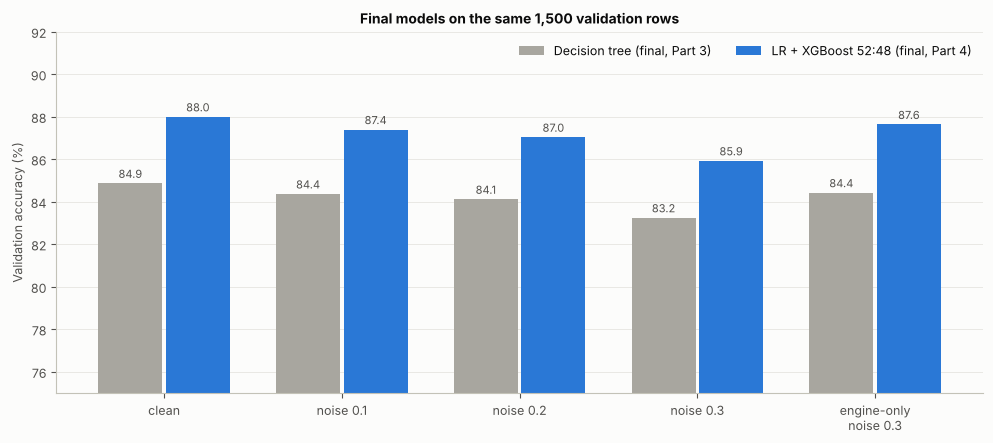

Blend minus decision tree (points): {'clean': 3.1, 'noisy_0.1': 3.0, 'noisy_0.2': 2.9, 'noisy_0.3': 2.7, 'engine_0.3': 3.2}


In [51]:
import matplotlib.pyplot as plt

# Part 4 re-used the names X, y, X_val, y_val for its own cross-validation -> rebuild the shared split
X = train_clean[FEATURE_COLUMNS]
y = train_clean[TARGET_COLUMN]
X_train, y_train = X[is_train].reset_index(drop=True), y[is_train].reset_index(drop=True)
X_val,   y_val   = X[~is_train].reset_index(drop=True), y[~is_train].reset_index(drop=True)


class Blend5248:
    """LR + XGBoost soft-voting blend with the Part 4 weights."""
    def fit(self, X, y):
        self.lr_ = build_logistic_regression().fit(X, y)
        self.xgb_ = build_xgboost().fit(X, y)
        return self
    def predict(self, X):
        p = W_LOGIT * self.lr_.predict_proba(X) + W_XGB * self.xgb_.predict_proba(X)
        return self.lr_.classes_[p.argmax(axis=1)]


compare_models = {
    "Decision tree (final, Part 3)": final_model,                 # trained on the 6,000 rows in Step 7
    "LR + XGBoost 52:48 (final, Part 4)": Blend5248().fit(X_train, y_train),
}
comparison = pd.DataFrame({name: val_scores(m) for name, m in compare_models.items()}).T * 100
comparison.to_csv(OUT_ROOT / "final_comparison_validation.csv")
display(comparison.round(1))

cols = ["clean", "noisy_0.1", "noisy_0.2", "noisy_0.3", "engine_0.3"]
labels_x = ["clean", "noise 0.1", "noise 0.2", "noise 0.3", "engine-only\nnoise 0.3"]
x = np.arange(len(cols))
fig, ax = plt.subplots(figsize=(10, 4.5))
for k, (name, color) in enumerate(zip(comparison.index, ["#a8a69f", "#2a78d6"])):
    bars = ax.bar(x + (k - 0.5) * 0.38, comparison.loc[name, cols], width=0.36, color=color, label=name)
    ax.bar_label(bars, labels=[f"{v:.1f}" for v in comparison.loc[name, cols]], padding=2, fontsize=8, color="#52514e")
ax.set_xticks(x, labels_x)
ax.set_ylim(75, 92)
ax.set_ylabel("Validation accuracy (%)")
ax.set_title("Final models on the same 1,500 validation rows")
ax.legend(loc="upper right", ncol=2)
ax.grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig(OUT_ROOT / "final_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

gap = comparison.iloc[1] - comparison.iloc[0]
print("Blend minus decision tree (points):", gap.round(1).to_dict())

## Conclusion

| | Decision tree (Part 3) | LR + XGBoost 52 : 48 (Part 4) |
|---|---|---|
| Inputs | 9 (4 block scores + 5 single features) | all 20 features |
| Robustness tools | block averaging, noise augmentation, large leaves | probability averaging of a linear and a boosted model |
| Interpretability | high (readable rules, Step 8) | lower (blend of two models) |
| Kaggle public | 86.8% | see Part 4 (50 : 50 version: 90.7%) |

- **EDA findings that drove every decision:** 2,500 duplicate rows (removed), class-specific capped values (kept), strong correlation blocks (size, power, height, efficiency), Sedans overlapping both other classes, and ≈ 0.25 sd extra noise on the engine features of the test data.
- **Decision tree:** the best single tree needed three robustness ideas — limiting complexity (depth 7, ≥ 40 rows per leaf), averaging correlated features to cancel noise, and training on noisy copies. Together they turned an over-fitted tree (100% train, 76.6% at noise 0.3 on validation) into a stable one (≈ 83–84% on noisy validation data).
- **Final model:** the blend of logistic regression (smooth linear boundaries) and XGBoost (non-linear thresholds) is about **3 points more accurate** (+2.7 to +3.2) than the best tree on the same validation rows, clean and noisy — the class boundaries are mostly linear, which a single tree can only approximate with steps.
- **Limit:** every model makes most of its errors on Sedans that overlap with SUVs or Sports Cars; ≈ 89–90% appears to be the practical ceiling for this data.

### Download all outputs (optional)
Zips `final_outputs/` (figures, tables, both submission files). On Colab the files are already in Google Drive; this also offers a download.

In [52]:
import shutil
archive = shutil.make_archive(str(OUT_ROOT.parent / "final_outputs"), "zip", OUT_ROOT)
print("Zipped to", archive)
if IN_COLAB:
    from google.colab import files
    files.download(archive)

Zipped to /home/claude/vv2/final/data/final_outputs.zip
